In [1]:
# Setup and data download

import os, zipfile, ssl, urllib.request, time, gc
import numpy as np
import pandas as pd

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


DEV_USERS = None
EVAL_N    = 20_000
DATA_DIR  = "data"
os.makedirs(DATA_DIR, exist_ok=True)
URL_32M   = "https://files.grouplens.org/datasets/movielens/ml-32m.zip"

def mem_gb():
    try:
        import psutil; return psutil.Process().memory_info().rss / 1e9
    except Exception: return float("nan")

def _fetch(url, dest):
    try:
        urllib.request.urlretrieve(url, dest)
    except urllib.error.URLError as e:
        if "CERTIFICATE_VERIFY_FAILED" not in str(e): raise
        print("Certificate verify failed, retrying with unverified SSL context...")
        ctx = ssl._create_unverified_context()
        with urllib.request.urlopen(url, context=ctx) as r, open(dest, "wb") as f:
            while chunk := r.read(1 << 20): f.write(chunk)

def download_ml32m():
    folder, zip_path = f"{DATA_DIR}/ml-32m", f"{DATA_DIR}/ml-32m.zip"
    need = ["ratings.csv", "movies.csv"]
    if all(os.path.exists(f"{folder}/{f}") for f in need):
        print("ml-32m already present.")
        return folder
    if not os.path.exists(zip_path):
        print("Downloading ml-32m (~239 MB) ...")
        _fetch(URL_32M, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        for f in need: z.extract(f"ml-32m/{f}", DATA_DIR)
    print("Done.")
    return folder

folder = download_ml32m()
print(os.listdir(folder))

Certificate verify failed, retrying with unverified SSL context...
Done.
['movies.csv', 'ratings.csv']


In [2]:
# Load the MovieLens data






def load_ml32m(folder=f"{DATA_DIR}/ml-32m", dev_users=DEV_USERS, seed=RANDOM_SEED):
    t0 = time.time()
    r = pd.read_csv(f"{folder}/ratings.csv", usecols=["userId", "movieId", "rating", "timestamp"],
                    dtype={"userId": "int32", "movieId": "int32", "rating": "float32", "timestamp": "int64"})
    assert r.timestamp.max() < 2**31, "timestamps no longer fit int32"
    r = r.rename(columns={"userId": "user_id", "movieId": "item_id"}).astype({"timestamp": "int32"})

    movies = pd.read_csv(f"{folder}/movies.csv", dtype={"movieId": "int32"}).rename(columns={"movieId": "item_id"})
    movies = movies.sort_values("item_id").reset_index(drop=True)

    movies["release_year"] = movies["title"].str.extract(r"\((\d{4})\)\s*$")[0].astype("float").astype("Int64")
    movies["title_raw"] = movies["title"]
    movies["title"] = movies["title"].str.replace(r"\s*\(\d{4}\)\s*$", "", regex=True)
    movies["genres"] = movies["genres"].replace("(no genres listed)", "Unknown")
    movies["genre_list"] = movies["genres"].str.split("|")

    if dev_users:
        rng = np.random.default_rng(seed)
        keep = rng.choice(r.user_id.unique(), size=dev_users, replace=False)
        r = r[r.user_id.isin(keep)]

    user_ids    = np.sort(r.user_id.unique())
    catalog_ids = movies.item_id.to_numpy()
    u = np.searchsorted(user_ids, r.user_id.to_numpy()).astype("int32")
    i = np.searchsorted(catalog_ids, r.item_id.to_numpy()).astype("int32")
    assert (catalog_ids[i] == r.item_id.to_numpy()).all(), "some rated movies are missing from movies.csv"
    r = pd.DataFrame({"u": u, "i": i, "rating": r.rating.to_numpy(), "timestamp": r.timestamp.to_numpy()})


    order = np.lexsort((r.i.to_numpy(), r.timestamp.to_numpy(), r.u.to_numpy()))
    r = r.iloc[order].reset_index(drop=True)
    print(f"loaded + indexed in {time.time() - t0:.0f}s | memory {mem_gb():.1f} GB")
    return r, movies, user_ids, catalog_ids

ratings, movies, user_ids, catalog_ids = load_ml32m()
N_USERS, N_ITEMS = len(user_ids), len(catalog_ids)
to_date = lambda ts: pd.to_datetime(np.asarray(ts, dtype="int64"), unit="s")
print(ratings.shape, movies.shape); display(ratings.head(3)); display(movies.head(3))


loaded + indexed in 53s | memory 1.3 GB
(32000204, 4) (87585, 6)


,u,i,rating,timestamp
0,0,2874,1.0,943226846
1,0,2905,4.0,943226846
2,0,2798,4.0,943226916


,item_id,title,genres,release_year,title_raw,genre_list
0,1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,1995,Toy Story (1995),"[Adventure, Animation, Children, Comedy, Fantasy]"
1,2,Jumanji,Adventure|Children|Fantasy,1995,Jumanji (1995),"[Adventure, Children, Fantasy]"
2,3,Grumpier Old Men,Comedy|Romance,1995,Grumpier Old Men (1995),"[Comedy, Romance]"


In [3]:
# Check the data before modelling


def sanity_report(ratings, movies):
    n_r = len(ratings)
    n_users, n_rated = ratings.u.nunique(), ratings.i.nunique()
    print(f"Users: {n_users:,} | Rated items: {n_rated:,} | Catalog (movies.csv): {len(movies):,}")
    print(f"Ratings: {n_r:,} | Sparsity: {1 - n_r/(n_users*N_ITEMS):.4%}")
    key = ratings.u.to_numpy().astype("int64") * N_ITEMS + ratings.i.to_numpy()
    print(f"Duplicate (user,item) pairs: {n_r - len(np.unique(key))}")
    print(f"Missing values:\n{ratings.isna().sum().to_string()}")
    print(f"Rating values: {[float(x) for x in sorted(ratings.rating.unique())]}  (half-star scale, unlike ml-1m)")
    ts = ratings.timestamp
    print(f"Date range: {to_date([ts.min()])[0]} -> {to_date([ts.max()])[0]}  (nothing after 2023: the newest titles are 2023 releases)")
    cnt = np.bincount(ratings.u, minlength=N_USERS)
    print(f"Min ratings per user: {cnt[cnt > 0].min()}")
    print(f"Movies with missing year: {movies.release_year.isna().sum()} | newest release year: {movies.release_year.max()}")
    print(f"Catalog items with zero ratings: {N_ITEMS - n_rated:,}  (matters for coverage later)")
    print(f"Sorted by (user, time)? {bool((np.diff(ratings.u.to_numpy()) >= 0).all())}")

sanity_report(ratings, movies)


Users: 200,948 | Rated items: 84,432 | Catalog (movies.csv): 87,585
Ratings: 32,000,204 | Sparsity: 99.8182%
Duplicate (user,item) pairs: 0
Missing values:
u            0
i            0
rating       0
timestamp    0
Rating values: [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]  (half-star scale, unlike ml-1m)
Date range: 1995-01-09 11:46:44 -> 2023-10-13 02:29:07  (nothing after 2023: the newest titles are 2023 releases)
Min ratings per user: 20
Movies with missing year: 617 | newest release year: 2023
Catalog items with zero ratings: 3,153  (matters for coverage later)
Sorted by (user, time)? True


In [4]:
# Choose a fixed set of evaluation users




def sample_users(candidates, n=EVAL_N, seed=RANDOM_SEED):
    """fixed random sample of whole users. 20k users still gives tight confidence intervals (reported later as +/-)"""
    rng = np.random.default_rng(seed)
    return np.sort(rng.choice(candidates, size=min(n, len(candidates)), replace=False))


In [5]:
# Popularity groups and concentration


import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")

def item_popularity(df):
    """ratings per catalog item (a numpy vector aligned with catalog_ids), items nobody rated get 0"""
    return np.bincount(df.i.to_numpy(), minlength=N_ITEMS)

def define_popularity_groups(pop, head_share=0.20, tail_share=0.20):
    """split items into head/mid/tail by cumulative share of ratings
    head = most popular items covering the first head_share of ratings
    tail = least popular items covering the last tail_share
    mid = the rest. unrated items always go to tail. returns an array of 0/1/2 (head/mid/tail) aligned with the catalog"""
    order = np.argsort(-pop, kind="stable")
    s = pop[order]
    cum_before = np.concatenate([[0.0], np.cumsum(s)[:-1]]) / s.sum()
    g = np.ones(len(pop), dtype=np.int8)
    g[cum_before < head_share] = 0
    g[cum_before >= 1 - tail_share] = 2
    g[s == 0] = 2
    out = np.empty(len(pop), dtype=np.int8); out[order] = g
    return out

GRP_NAMES = ["head", "mid", "tail"]

def gini(x):
    """gini: 0 = everything equal, 1 = all attention on one item"""
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x); i = np.arange(1, n + 1)
    return (2 * (i * x).sum()) / (n * x.sum()) - (n + 1) / n

pop    = item_popularity(ratings)
groups = define_popularity_groups(pop)

group_summary = pd.DataFrame({"n_ratings": pop, "group": pd.Categorical.from_codes(groups, GRP_NAMES)}).groupby("group", observed=True).agg(
    n_items=("n_ratings", "size"), n_ratings=("n_ratings", "sum"), min_ratings=("n_ratings", "min"), max_ratings=("n_ratings", "max"))
group_summary["pct_of_catalog"] = 100 * group_summary.n_items / group_summary.n_items.sum()
group_summary["pct_of_ratings"] = 100 * group_summary.n_ratings / group_summary.n_ratings.sum()

print(group_summary.round(2))
print(f"\nGini of ratings across catalog items: {gini(pop):.3f}")
print(f"Median ratings per item: {np.median(pop):.0f} | Mean: {pop.mean():.0f} | Max: {pop.max()}")


       n_items  n_ratings  min_ratings  max_ratings  pct_of_catalog  \
group                                                                 
head       138    6425356        30312       102929            0.16   
mid       2401   19177208         2425        29900            2.74   
tail     85046    6397640            0         2423           97.10   

       pct_of_ratings  
group                  
head            20.08  
mid             59.93  
tail            19.99  

Gini of ratings across catalog items: 0.954
Median ratings per item: 5 | Mean: 365 | Max: 102929


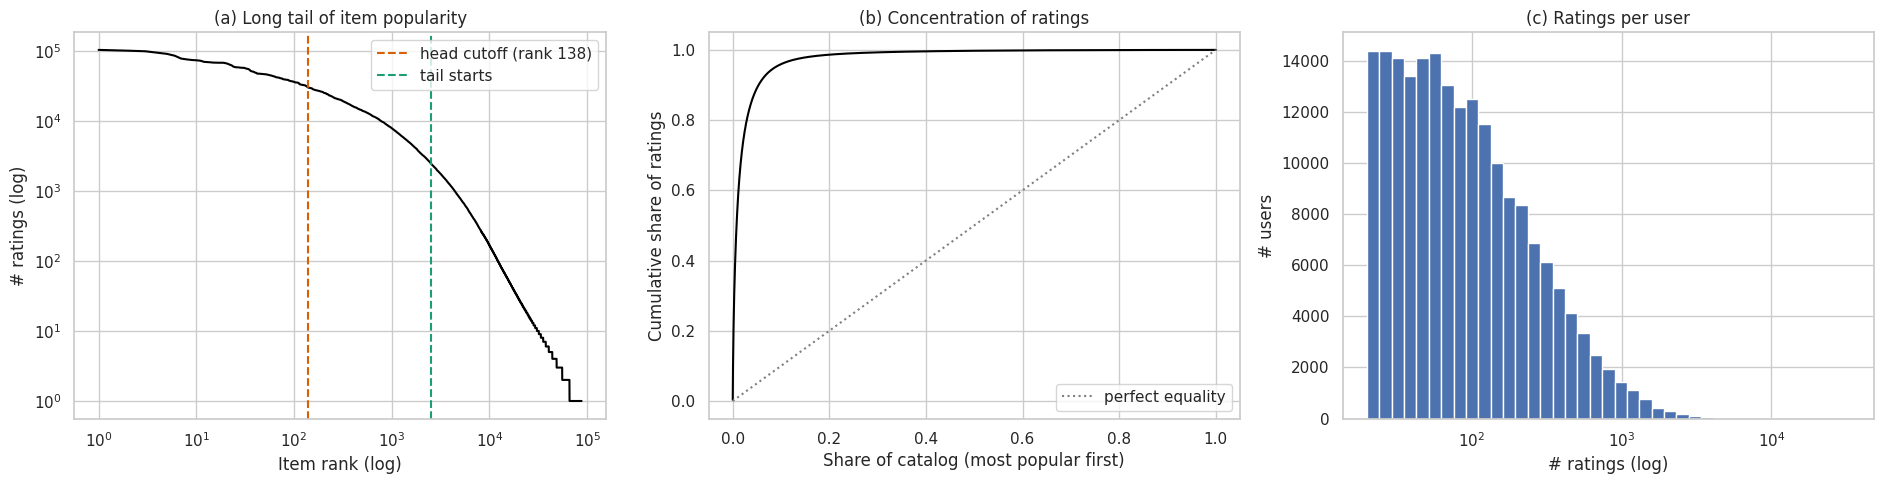

count    200948.0
mean        159.2
std         282.0
min          20.0
10%          25.0
25%          36.0
50%          73.0
75%         167.0
90%         364.0
99%        1290.0
max       33332.0
dtype: float64


In [6]:
# Look at the long tail and user activity


user_counts = pd.Series(np.bincount(ratings.u, minlength=N_USERS))
ranked = np.sort(pop)[::-1]
rank = np.arange(1, len(ranked) + 1)
colors = {"head": "#d95f02", "mid": "#7570b3", "tail": "#1b9e77"}

fig, axes = plt.subplots(1, 3, figsize=(19, 5))


ax = axes[0]
ax.loglog(rank, np.clip(ranked, 1, None), color="black")
n_head = (groups == 0).sum(); n_tail = (groups == 2).sum()
ax.axvline(n_head, color=colors["head"], ls="--", label=f"head cutoff (rank {n_head})")
ax.axvline(len(ranked) - n_tail, color=colors["tail"], ls="--", label="tail starts")
ax.set(title="(a) Long tail of item popularity", xlabel="Item rank (log)", ylabel="# ratings (log)")
ax.legend()


ax = axes[1]
ax.plot(rank / len(ranked), np.cumsum(ranked) / ranked.sum(), color="black")
ax.plot([0, 1], [0, 1], ls=":", color="grey", label="perfect equality")
ax.set(title="(b) Concentration of ratings", xlabel="Share of catalog (most popular first)",
       ylabel="Cumulative share of ratings")
ax.legend()


ax = axes[2]
ax.hist(user_counts, bins=np.logspace(np.log10(user_counts.min()), np.log10(user_counts.max()), 40), color="#4c72b0")
ax.set_xscale("log")
ax.set(title="(c) Ratings per user", xlabel="# ratings (log)", ylabel="# users")
plt.tight_layout(); plt.show()

print(user_counts.describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(1))


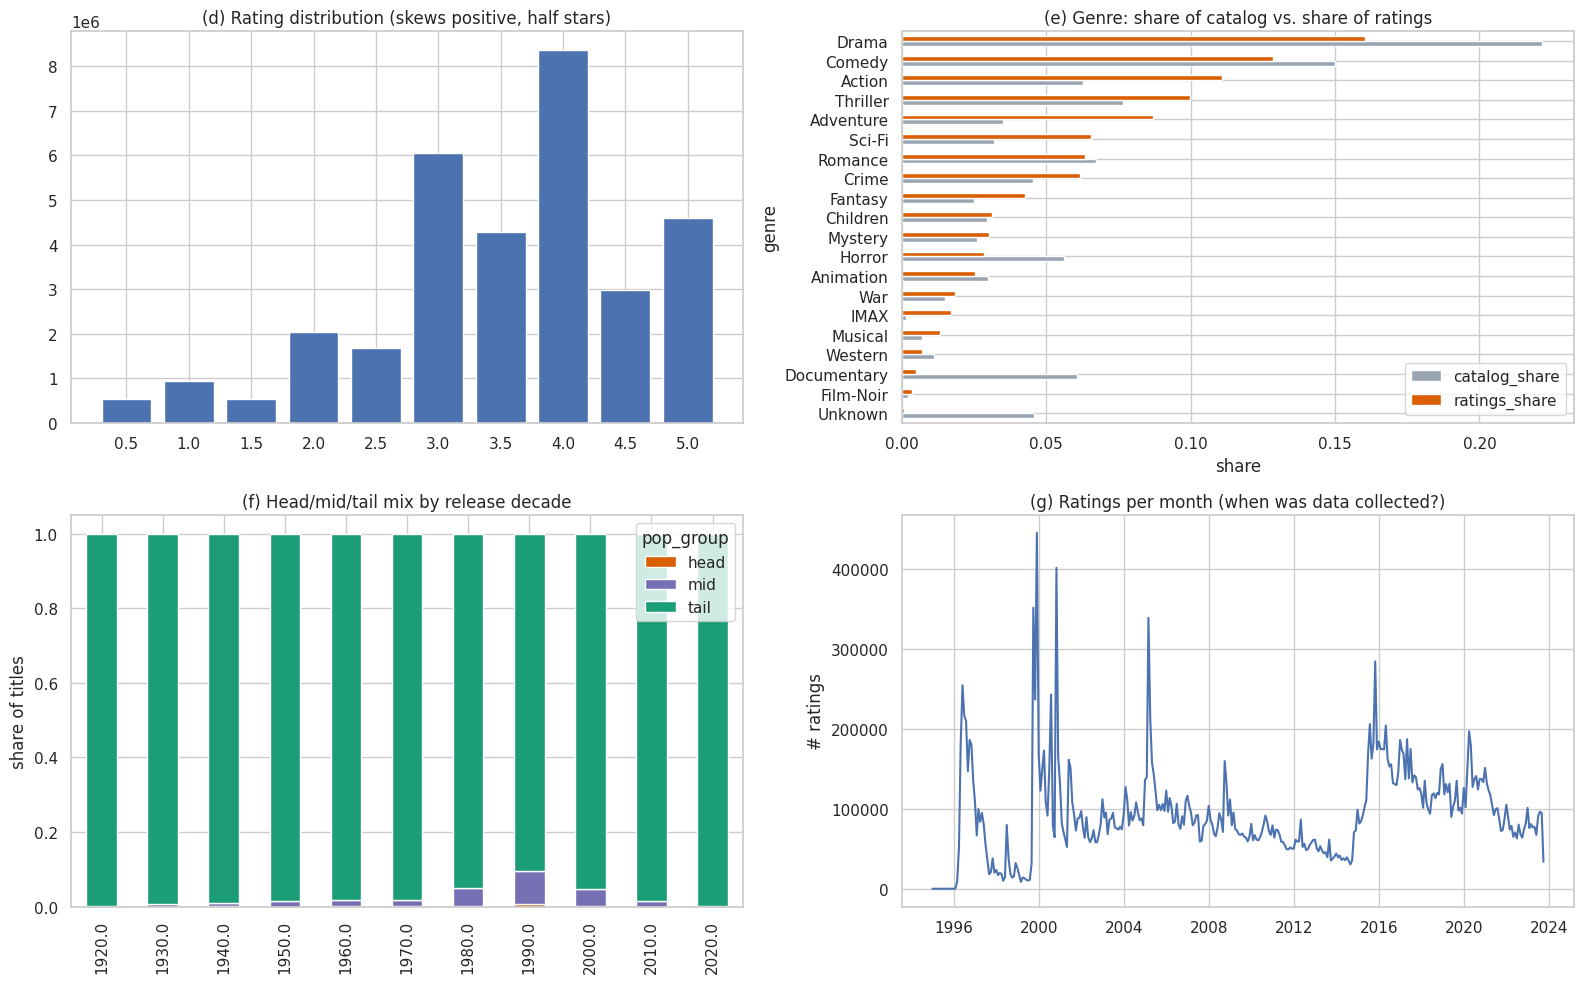

             catalog_share  ratings_share  attention_ratio
genre                                                     
Unknown              0.046          0.001            0.014
Film-Noir            0.002          0.003            1.528
Documentary          0.061          0.005            0.081
Western              0.011          0.007            0.623
Musical              0.007          0.013            1.938
IMAX                 0.001          0.017           13.560
War                  0.015          0.018            1.213
Animation            0.030          0.025            0.849
Horror               0.056          0.029            0.510
Mystery              0.026          0.030            1.153
Children             0.029          0.031            1.070
Fantasy              0.025          0.043            1.702
Crime                0.045          0.062            1.363
Romance              0.067          0.063            0.943
Sci-Fi               0.032          0.066            2.0

In [7]:
# Explore genres, years and rating patterns




g_long = movies[["item_id", "genre_list"]].reset_index().explode("genre_list").rename(columns={"index": "i", "genre_list": "genre"})
g_long["n_ratings"] = pop[g_long.i.to_numpy()]
cat_share = g_long.groupby("genre").size()
rat_share = g_long.groupby("genre").n_ratings.sum()
genre_table = pd.DataFrame({"catalog_share": cat_share / cat_share.sum(),
                            "ratings_share": rat_share / rat_share.sum()})
genre_table["attention_ratio"] = genre_table.ratings_share / genre_table.catalog_share
genre_table = genre_table.sort_values("ratings_share")


movies["decade"] = ((movies.release_year.astype("float") // 10) * 10).clip(lower=1920)
movies["n_ratings"] = pop
movies["pop_group"] = pd.Categorical.from_codes(groups, GRP_NAMES)
decade_table = movies.groupby("decade").agg(n_titles=("item_id", "size"),
                                            total_ratings=("n_ratings", "sum"),
                                            median_ratings_per_title=("n_ratings", "median"))
decade_group_mix = pd.crosstab(movies.decade, movies.pop_group, normalize="index")[GRP_NAMES]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

rv = ratings.rating.value_counts().sort_index()
axes[0, 0].bar(rv.index.astype(str), rv.values, color="#4c72b0")
axes[0, 0].set(title="(d) Rating distribution (skews positive, half stars)")

genre_table[["catalog_share", "ratings_share"]].plot.barh(ax=axes[0, 1], color=["#9aa5b1", "#d95f02"])
axes[0, 1].set(title="(e) Genre: share of catalog vs. share of ratings", xlabel="share")

decade_group_mix.plot.bar(stacked=True, ax=axes[1, 0], color=[colors[c] for c in GRP_NAMES])
axes[1, 0].set(title="(f) Head/mid/tail mix by release decade", ylabel="share of titles", xlabel="")

months = ratings.timestamp.to_numpy().astype("datetime64[s]").astype("datetime64[M]")
mo, mc = np.unique(months, return_counts=True)
axes[1, 1].plot(mo, mc, color="#4c72b0")
axes[1, 1].set(title="(g) Ratings per month (when was data collected?)", ylabel="# ratings")
plt.tight_layout(); plt.show()

print(genre_table.round(3)); print(); print(decade_table); print(); print(decade_group_mix.round(2))


In [8]:
# Compare average ratings across popularity groups


item_mean = np.bincount(ratings.i, weights=ratings.rating, minlength=N_ITEMS) / np.maximum(pop, 1)
chk = (pd.DataFrame({"mean_rating": item_mean, "group": pd.Categorical.from_codes(groups, GRP_NAMES)})[pop > 0]
       .groupby("group", observed=True).mean_rating.agg(["mean", "median", "count"]))
print(chk.round(2))
print("(items with a handful of ratings have noisy means, which is why the tail looks more extreme in both directions)")


       mean  median  count
group                     
head   3.86    3.94    138
mid    3.45    3.52   2401
tail   2.99    3.04  81893
(items with a handful of ratings have noisy means, which is why the tail looks more extreme in both directions)


In [9]:
# Create time-based train, validation and test splits


from dataclasses import dataclass
from scipy import sparse

REL_THRESHOLD = 4
TRAIN_FRAC, VAL_FRAC = 0.70, 0.10

@dataclass
class Split:
    train: pd.DataFrame; val: pd.DataFrame; test: pd.DataFrame; name: str

def per_user_temporal_split(ratings, train_frac=TRAIN_FRAC, val_frac=VAL_FRAC):
    """main split. per user: time order, first 70% train, next 10% val (tune here), last 20% test (only look at it once at the end).
    The table is already sorted by (user, time, item), so a row's position inside its user's block is all we need.
    timestamp ties are broken by item index, so it is reproducible"""
    u, ts = ratings.u.to_numpy(), ratings.timestamp.to_numpy().astype("int64")
    same_user = np.diff(u) == 0
    assert (np.diff(u) >= 0).all() and (np.diff(ts)[same_user] >= 0).all(), "ratings must be sorted by (user, time)"
    counts = np.bincount(u, minlength=N_USERS)
    start = np.cumsum(counts) - counts
    pos = np.arange(len(u)) - np.repeat(start, counts)
    frac = pos / np.repeat(counts, counts)
    code = np.where(frac < train_frac, 0, np.where(frac < train_frac + val_frac, 1, 2)).astype("int8")
    del pos, frac
    return Split(*[ratings[code == k].reset_index(drop=True) for k in range(3)], "per-user temporal")

def global_time_split(ratings, train_frac=0.70, val_frac=0.15):
    """robustness check: one calendar cutoff for everyone (stricter, fewer users to evaluate)"""
    ts = ratings.timestamp.to_numpy(); s = np.sort(ts); n = len(s)
    t1, t2 = s[int(n * train_frac)], s[int(n * (train_frac + val_frac))]
    return Split(ratings[ts < t1].reset_index(drop=True), ratings[(ts >= t1) & (ts < t2)].reset_index(drop=True),
                 ratings[ts >= t2].reset_index(drop=True), "global time cutoff")

def pair_keys(df): return df.u.to_numpy().astype("int64") * N_ITEMS + df.i.to_numpy()

def leakage_checks(sp):
    """stop right away if the split is broken"""
    k = {n: pair_keys(getattr(sp, n)) for n in ["train", "val", "test"]}
    for a, b in [("train", "val"), ("val", "test"), ("train", "test")]:
        overlap = len(np.intersect1d(k[a], k[b], assume_unique=True))
        assert overlap == 0, f"{overlap} (user,item) pairs shared by {a} and {b}"
    if sp.name.startswith("per-user"):
        last_tr  = pd.Series(sp.train.timestamp.to_numpy()).groupby(sp.train.u.to_numpy()).max()
        first_te = pd.Series(sp.test.timestamp.to_numpy()).groupby(sp.test.u.to_numpy()).min()
        j = pd.concat([last_tr, first_te], axis=1, keys=["a", "b"]).dropna()
        assert (j.a <= j.b).all(), "a user's train data extends past their test data"
    print(f"[{sp.name}] leakage checks passed. (memory {mem_gb():.1f} GB)")

sp   = per_user_temporal_split(ratings);  leakage_checks(sp)
sp_g = global_time_split(ratings);        leakage_checks(sp_g)


[per-user temporal] leakage checks passed. (memory 2.0 GB)
[global time cutoff] leakage checks passed. (memory 2.5 GB)


In [10]:
# Build the matrices used by the models


def split_report(sp):
    """popularity groups come from train only (this is the leakage fix from stage 2)"""
    g = define_popularity_groups(item_popularity(sp.train))
    te_rel = sp.test[sp.test.rating >= REL_THRESHOLD]
    print(f"[{sp.name}]")
    print(f"  rows train/val/test: {len(sp.train):,} / {len(sp.val):,} / {len(sp.test):,}")
    print(f"  users with >=1 relevant test item: {te_rel.u.nunique():,} of {N_USERS:,}")
    in_train = np.zeros(N_ITEMS, bool); in_train[sp.train.i.to_numpy()] = True
    print(f"  test rows on items never seen in train: {(~in_train[sp.test.i.to_numpy()]).mean():.2%}")
    print(f"  relevance rate (rating>={REL_THRESHOLD}) in test: {(sp.test.rating >= REL_THRESHOLD).mean():.1%}")
    mix = pd.Series(g[te_rel.i.to_numpy()]).value_counts(normalize=True).reindex([0, 1, 2]); mix.index = GRP_NAMES
    print("  share of RELEVANT test interactions by train-popularity group (real demand):")
    print(mix.round(3).to_string())
    return g

GRP = split_report(sp)
_   = split_report(sp_g)
pop_train = item_popularity(sp.train)

def to_csr(df, value="binary"):
    """sparse user x item matrix: ~32M nonzeros instead of 17.6 billion dense cells"""
    v = np.ones(len(df), "float32") if value == "binary" else df.rating.to_numpy(dtype="float32")
    return sparse.csr_matrix((v, (df.u.to_numpy(), df.i.to_numpy())), shape=(N_USERS, N_ITEMS))

X_train_ratings = to_csr(sp.train, "rating")
X_train_pos     = to_csr(sp.train[sp.train.rating >= REL_THRESHOLD])
X_seen_val      = X_train_ratings
X_seen_test     = to_csr(pd.concat([sp.train, sp.val]))
print(f"X_train_ratings {X_train_ratings.shape}, nnz {X_train_ratings.nnz:,} | liked nnz {X_train_pos.nnz:,} | memory {mem_gb():.1f} GB")


[per-user temporal]
  rows train/val/test: 22,488,423 / 3,189,107 / 6,322,674
  users with >=1 relevant test item: 196,523 of 200,948
  test rows on items never seen in train: 0.40%
  relevance rate (rating>=4) in test: 46.5%
  share of RELEVANT test interactions by train-popularity group (real demand):
head    0.145
mid     0.584
tail    0.271
[global time cutoff]
  rows train/val/test: 22,400,142 / 4,800,031 / 4,800,031
  users with >=1 relevant test item: 29,997 of 200,948
  test rows on items never seen in train: 18.85%
  relevance rate (rating>=4) in test: 49.5%
  share of RELEVANT test interactions by train-popularity group (real demand):
head    0.179
mid     0.456
tail    0.365
X_train_ratings (200948, 87585), nnz 22,488,423 | liked nnz 11,513,286 | memory 2.9 GB


In [11]:
# Set up ranking ground truth and evaluation users


def relevant_dict(df, users, thr=REL_THRESHOLD):
    """{user_index: set of relevant item_indices}, only for the users we evaluate (a dict for all 200k would waste GBs)"""
    pos = df[(df.rating >= thr) & np.isin(df.u.to_numpy(), users)]
    return pos.groupby("u")["i"].apply(set).to_dict()



has_val  = np.bincount(sp.val[sp.val.rating >= REL_THRESHOLD].u,  minlength=N_USERS) > 0
has_test = np.bincount(sp.test[sp.test.rating >= REL_THRESHOLD].u, minlength=N_USERS) > 0
eligible = np.flatnonzero(has_val & has_test)
EVAL_USERS = sample_users(eligible, EVAL_N)
VAL_USERS = TEST_USERS = EVAL_USERS
val_rel, test_rel = relevant_dict(sp.val, EVAL_USERS), relevant_dict(sp.test, EVAL_USERS)
print(f"eligible users: {len(eligible):,} of {N_USERS:,} | evaluated: {len(EVAL_USERS):,} (fixed random sample, seed {RANDOM_SEED})")
print(f"avg relevant items per eval user - val: {np.mean([len(v) for v in val_rel.values()]):.1f}, test: {np.mean([len(v) for v in test_rel.values()]):.1f}")
print(X_train_ratings.shape, X_train_ratings.nnz, X_train_pos.nnz)


eligible users: 185,884 of 200,948 | evaluated: 20,000 (fixed random sample, seed 42)
avg relevant items per eval user - val: 7.9, test: 15.6
(200948, 87585) 22488423 11513286


In [12]:
# Ranking metrics and baseline recommenders


TOPK = 10

def topk_recommend(score_fn, users, X_seen, K=TOPK, batch=500):
    """top-k for any model with score_fn(user_idx_batch) -> (batch x n_items) scores.
    scores 500 users at a time (500 x 87k floats = ~175 MB, a 1000-user batch would double that), hides items the user already saw (-inf),
    returns item indices, best first"""
    users = np.asarray(users); out = np.empty((len(users), K), dtype=np.int32)
    for s in range(0, len(users), batch):
        b = users[s:s + batch]
        scores = np.array(score_fn(b), dtype=np.float32)
        r, c = X_seen[b].nonzero(); scores[r, c] = -np.inf
        part = np.argpartition(-scores, K, axis=1)[:, :K]
        order = np.argsort(-np.take_along_axis(scores, part, 1), axis=1)
        out[s:s + batch] = np.take_along_axis(part, order, 1)
    return out

def evaluate_recs(recs, users, truth, K=TOPK):
    """per-user precision@k, recall@k, ndcg@k (binary relevance). keeps per-user rows so I can do CIs later"""
    recs = recs[:, :K]
    disc = 1.0 / np.log2(np.arange(2, K + 2))
    rows = []
    for row, u in zip(recs, users):
        rel = truth[u]
        hit = np.array([it in rel for it in row], dtype=float)
        n_hit = hit.sum()
        idcg = disc[:min(K, len(rel))].sum()
        rows.append((n_hit / K, n_hit / len(rel), (hit * disc).sum() / idcg))
    return pd.DataFrame(rows, columns=["precision", "recall", "ndcg"], index=users)


class RandomModel:
    def __init__(self, seed=RANDOM_SEED): self.rng = np.random.default_rng(seed)
    def fit(self, X_ratings, X_pos): self.n = X_ratings.shape[1]; return self
    def score(self, b): return self.rng.random((len(b), self.n), dtype=np.float32)

class PopularityModel:
    """score = number of train ratings, same list for everyone"""
    def fit(self, X_ratings, X_pos):
        self.s = np.asarray((X_ratings > 0).sum(axis=0)).ravel().astype(np.float32); return self
    def score(self, b): return np.broadcast_to(self.s, (len(b), len(self.s)))

class WeightedRatingModel:
    """imdb weighted rating: pull each item's mean rating towards the global mean"""
    def __init__(self, m=100): self.m = m
    def fit(self, X_ratings, X_pos):
        v = np.asarray((X_ratings > 0).sum(axis=0)).ravel().astype(np.float32)
        tot = np.asarray(X_ratings.sum(axis=0)).ravel().astype(np.float32)
        R = np.divide(tot, v, out=np.zeros_like(tot), where=v > 0)
        C = X_ratings.data.mean()
        self.s = (v / (v + self.m)) * R + (self.m / (v + self.m)) * C; return self
    def score(self, b): return np.broadcast_to(self.s, (len(b), len(self.s)))





KNN_MIN_LIKES, KNN_MAX_K, _KNN_CACHE = 20, 200, {}

def build_knn_index(X_pos, min_likes=KNN_MIN_LIKES, kmax=KNN_MAX_K, block=1500):
    """cosine item-item neighbours on liked items (train only). returns (items_kept, neighbour_ids, neighbour_sims), neighbours sorted best first"""
    X = X_pos.tocsc().astype(np.float32)
    cnt = np.diff(X.indptr); keep = np.flatnonzero(cnt >= min_likes)
    Xn = (X[:, keep] @ sparse.diags(1.0 / np.sqrt(cnt[keep]).astype(np.float32))).tocsr()
    XnT = Xn.T.tocsr(); kk = min(kmax, len(keep) - 1)
    nb_id = np.empty((len(keep), kk), np.int32); nb_sim = np.empty((len(keep), kk), np.float32); t0 = time.time()
    for s in range(0, len(keep), block):
        S = (XnT[s:s + block] @ Xn).toarray()
        S[np.arange(S.shape[0]), np.arange(s, s + S.shape[0])] = 0
        idx = np.argpartition(-S, kk - 1, axis=1)[:, :kk]; v = np.take_along_axis(S, idx, 1)
        o = np.argsort(-v, axis=1)
        nb_id[s:s + block] = keep[np.take_along_axis(idx, o, 1)]; nb_sim[s:s + block] = np.take_along_axis(v, o, 1)
        if (s // block) % 10 == 0: print(f"  kNN index: {min(s + block, len(keep)):,}/{len(keep):,} items ({time.time() - t0:.0f}s)", flush=True)
    return keep, nb_id, nb_sim

class ItemKNN:
    """item-based CF on liked items (rating >= 4): cosine similarity, top-k neighbours per item.
    The expensive neighbour search runs once on the train data; every k just keeps the first k neighbours"""
    def __init__(self, k=50): self.k = k
    def fit(self, X_ratings, X_pos):
        key = (X_pos.shape, X_pos.nnz)
        if key not in _KNN_CACHE: _KNN_CACHE[key] = build_knn_index(X_pos)
        keep, nb_id, nb_sim = _KNN_CACHE[key]; k = min(self.k, nb_id.shape[1])
        rows = np.repeat(keep, k)
        self.S = sparse.csr_matrix((nb_sim[:, :k].ravel(), (rows, nb_id[:, :k].ravel())), shape=(X_pos.shape[1],) * 2)
        self.hist = X_pos.tocsr().astype(np.float32); return self
    def score(self, b): return (self.hist[b] @ self.S.T).toarray()

def fit_eval(model, users, truth, X_seen, K=TOPK):
    model.fit(X_train_ratings, X_train_pos)
    recs = topk_recommend(model.score, users, X_seen, K)
    return recs, evaluate_recs(recs, users, truth, K)


In [13]:
# Tune the baseline models on validation data


WR_GRID  = [50, 100, 250, 500, 1000, 2000, 5000, 10000]
KNN_GRID = [20, 50, 100, 200]

def tune(make_model, grid, name):
    rows = []
    for p in grid:
        _, pu = fit_eval(make_model(p), VAL_USERS, val_rel, X_seen_val)
        rows.append({name: p, **pu.mean().round(4).to_dict()})
    df = pd.DataFrame(rows); print(df.to_string(index=False))
    best = df.loc[df.ndcg.idxmax(), name]
    print(f"-> best {name} on validation (by NDCG@{TOPK}): {best}\n")
    return best

t0 = time.time()
best_m = tune(lambda m: WeightedRatingModel(m), WR_GRID,  "m")
best_m = int(best_m)
print("building the item-kNN neighbour index (one pass over the train data, a few minutes at full scale) ...")
best_k = int(tune(lambda k: ItemKNN(k), KNN_GRID, "k"))
print(f"stage 4 tuning done in {time.time() - t0:.0f}s | memory {mem_gb():.1f} GB")


    m  precision  recall   ndcg
   50     0.0099  0.0191 0.0173
  100     0.0126  0.0230 0.0197
  250     0.0130  0.0233 0.0218
  500     0.0178  0.0335 0.0300
 1000     0.0194  0.0357 0.0319
 2000     0.0210  0.0389 0.0364
 5000     0.0258  0.0488 0.0428
10000     0.0283  0.0530 0.0461
-> best m on validation (by NDCG@10): 10000

building the item-kNN neighbour index (one pass over the train data, a few minutes at full scale) ...
  kNN index: 1,500/11,671 items (5s)
  k  precision  recall   ndcg
 20     0.0590  0.1164 0.0993
 50     0.0599  0.1178 0.1006
100     0.0599  0.1176 0.1007
200     0.0598  0.1170 0.1004
-> best k on validation (by NDCG@10): 100

stage 4 tuning done in 338s | memory 3.0 GB


In [14]:
# Run the final baseline evaluation


models = {
    "Random":                       RandomModel(),
    "Global popularity":            PopularityModel(),
    f"Weighted-rating pop (m={best_m})": WeightedRatingModel(best_m),
    f"Item-kNN CF (k={best_k})":     ItemKNN(best_k),
}

RECS_TEST, PER_USER_TEST, rows = {}, {}, []
for name, mdl in models.items():
    recs, pu = fit_eval(mdl, TEST_USERS, test_rel, X_seen_test)
    RECS_TEST[name], PER_USER_TEST[name] = recs, pu
    m = pu.mean(); ci = 1.96 * pu.std() / np.sqrt(len(pu))
    rows.append({"model": name,
                 f"Precision@{TOPK}": f"{m.precision:.4f} ± {ci.precision:.4f}",
                 f"Recall@{TOPK}":    f"{m.recall:.4f} ± {ci.recall:.4f}",
                 f"NDCG@{TOPK}":      f"{m.ndcg:.4f} ± {ci.ndcg:.4f}"})

baseline_table = pd.DataFrame(rows).set_index("model")
print(f"Evaluated on {len(TEST_USERS):,} users, K={TOPK}. ± = 95% CI over users.")
display(baseline_table)


Evaluated on 20,000 users, K=10. ± = 95% CI over users.


,Precision@10,Recall@10,NDCG@10
model,,,
Random,0.0001 ± 0.0001,0.0001 ± 0.0000,0.0001 ± 0.0001
Global popularity,0.0576 ± 0.0015,0.0518 ± 0.0016,0.0733 ± 0.0019
Weighted-rating pop (m=10000),0.0507 ± 0.0014,0.0467 ± 0.0016,0.0643 ± 0.0018
Item-kNN CF (k=100),0.0918 ± 0.0018,0.0887 ± 0.0022,0.1182 ± 0.0024


In [15]:
# Fit the factorisation and content-based models



try:
    import implicit
except ImportError:
    import subprocess, sys
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "implicit"], capture_output=True, text=True, timeout=600)
    print("installed implicit" if r.returncode == 0 else "COULD NOT install implicit:\n" + r.stderr[-400:])
from scipy.sparse.linalg import svds
import itertools

class PureSVD:
    """truncated svd of the liked-items matrix. score(u,i) = (U_u * s) . V_i"""
    def __init__(self, factors=30): self.f = factors
    def fit(self, X_ratings, X_pos):
        U, s, Vt = svds(X_pos.astype(np.float32), k=self.f, random_state=RANDOM_SEED)
        self.UF = (U * s).astype(np.float32); self.V = Vt.astype(np.float32)
        self.fitted_ = True; return self
    def score(self, b): return self.UF[b] @ self.V

def confidence_matrix(X_pos, alpha, w=None):
    """c_ui = 1 + alpha * w_i for every liked (user, item) pair (Hu, Koren & Volinsky 2008); w = per-item weight, None = all 1"""
    C = X_pos.tocsr().astype(np.float32); C.data = (1.0 + alpha * (1.0 if w is None else w[C.indices])).astype(np.float32); return C

def _half_step(C, Y, reg):
    """numpy fallback: solve one side's factors while the other side Y is fixed. A = Y'Y + sum (c-1) y y' + reg I, b = sum c y"""
    f = Y.shape[1]; YtY = Y.T @ Y; reg_I = reg * np.eye(f); out = np.zeros((C.shape[0], f))
    for u in range(C.shape[0]):
        s, e = C.indptr[u], C.indptr[u + 1]
        if e == s: continue
        Yu = Y[C.indices[s:e]]; c = C.data[s:e].astype(np.float64)
        out[u] = np.linalg.solve(YtY + (Yu * (c - 1)[:, None]).T @ Yu + reg_I, (c[:, None] * Yu).sum(axis=0))
    return out

def als_fit(C, factors, reg, iters, seed=RANDOM_SEED):
    """implicit-feedback ALS on a confidence matrix. uses the `implicit` library when installed (fast, multi-core),
    otherwise a plain numpy version that is only practical on small samples. returns user and item factors (float32)"""
    try:
        from implicit.als import AlternatingLeastSquares
        m = AlternatingLeastSquares(factors=factors, regularization=reg, iterations=iters, alpha=1.0,
                                    calculate_training_loss=False, random_state=seed)
        m.fit(C, show_progress=False)
        as_np = lambda M: M.to_numpy() if hasattr(M, "to_numpy") else np.asarray(M)
        return as_np(m.user_factors).astype(np.float32), as_np(m.item_factors).astype(np.float32)
    except ImportError:
        if C.shape[0] * C.shape[1] > 5e8: raise RuntimeError("install `implicit` (pip install implicit): the numpy fallback is far too slow at this size")
        print("  [implicit not installed: using the slow numpy fallback, fine for samples only]")
        rng = np.random.default_rng(seed); Ct = C.T.tocsr()
        Q = rng.normal(0, 0.01, (C.shape[1], factors))
        for _ in range(iters):
            P = _half_step(C, Q, reg); Q = _half_step(Ct, P, reg)
        return P.astype(np.float32), Q.astype(np.float32)

class ImplicitALS:
    """implicit ALS. gamma = 0: plain (confidence 1 + alpha for liked items). gamma > 0: inverse-popularity weighting (stage 7),
    a liked item's confidence is 1 + alpha * w_item with w ~ count^(-gamma), rescaled so the average weight over all likes is 1"""
    def __init__(self, factors=64, reg=50.0, alpha=2.0, iters=10, gamma=0.0):
        self.f, self.reg, self.alpha, self.iters, self.g = factors, reg, alpha, iters, gamma
    def fit(self, X_ratings, X_pos):
        cnt = np.maximum(np.asarray(X_pos.sum(axis=0)).ravel(), 1)
        w = cnt ** (-self.g); self.w = w / ((cnt * w).sum() / cnt.sum())
        self.P, self.Q = als_fit(confidence_matrix(X_pos, self.alpha, self.w), self.f, self.reg, self.iters)
        self.fitted_ = True; return self
    def score(self, b): return self.P[b] @ self.Q.T

class ContentModel:
    """user profile = mean of the (idf-weighted genre + release decade) vectors of liked items, score = cosine"""
    def __init__(self, decade_weight=0.5): self.dw = decade_weight
    def fit(self, X_ratings, X_pos):
        genres = sorted({g for gl in movies.genre_list for g in gl})
        gi = {g: i for i, g in enumerate(genres)}
        G = np.zeros((len(movies), len(genres)), np.float32)
        for r, gl in enumerate(movies.genre_list): G[r, [gi[g] for g in gl]] = 1
        idf = np.log(len(movies) / (1 + G.sum(axis=0))) + 1
        yr = movies.release_year.astype("float"); yr = yr.fillna(yr.median()).to_numpy()
        decade = np.clip((yr // 10) * 10, 1920, None).astype(int)
        D = (decade[:, None] == np.unique(decade)[None, :]).astype(np.float32) * self.dw
        F = np.hstack([G * idf, D]); F /= np.linalg.norm(F, axis=1, keepdims=True)
        self.F = F
        self.hist = X_pos.tocsr().astype(np.float32); self.fitted_ = True; return self
    def score(self, b):
        prof = self.hist[b] @ self.F
        prof /= np.maximum(np.linalg.norm(prof, axis=1, keepdims=True), 1e-9)
        return prof @ self.F.T

def _z(s): return (s - s.mean(axis=1, keepdims=True)) / (s.std(axis=1, keepdims=True) + 1e-9)

class Hybrid:
    """alpha*z(cf) + (1-alpha)*z(content). the parts are fitted once and reused for every alpha"""
    def __init__(self, cf, content, alpha=0.8): self.cf, self.content, self.alpha = cf, content, alpha
    def fit(self, X_ratings, X_pos):
        for c in (self.cf, self.content):
            if not getattr(c, "fitted_", False): c.fit(X_ratings, X_pos)
        return self
    def score(self, b): return self.alpha * _z(self.cf.score(b)) + (1 - self.alpha) * _z(self.content.score(b))


installed implicit


In [16]:
# Choose model settings using validation results




ALS_FACTORS = 64
FAST = False
def tune_grid(make_model, grid, label):
    """grid: dict of param -> list of values. returns (best_params, best_val_ndcg)"""
    rows = []
    for vals in itertools.product(*grid.values()):
        p = dict(zip(grid.keys(), vals)); t0 = time.time()
        _, pu = fit_eval(make_model(**p), VAL_USERS, val_rel, X_seen_val)
        rows.append({**p, **pu.mean().round(4).to_dict(), "sec": round(time.time() - t0)})
    df = pd.DataFrame(rows).sort_values("ndcg", ascending=False).reset_index(drop=True)
    print(f"--- {label} (validation, sorted by NDCG@{TOPK}) ---"); print(df.to_string(index=False))
    best = df.iloc[0]
    best_p = {k: (int(best[k]) if k == "factors" else float(best[k])) for k in grid}
    print(f"-> best: {best_p}\n")
    return best_p, float(best.ndcg)

svd_p, svd_ndcg = tune_grid(lambda factors: PureSVD(factors), {"factors": [10, 30, 60] if FAST else [10, 20, 30, 40, 60]}, "PureSVD")
mk_als = lambda factors, reg, alpha: ImplicitALS(factors, reg, alpha, iters=10)
p1, n1 = tune_grid(mk_als, {"factors": [ALS_FACTORS], "reg": [10, 50] if FAST else [1, 10, 50], "alpha": [2]}, "Implicit ALS, step 1: regularisation")
if FAST: als_p, als_ndcg = p1, n1
else:
    p2, n2 = tune_grid(mk_als, {"factors": [ALS_FACTORS], "reg": [p1["reg"]], "alpha": [1, 5]}, "Implicit ALS, step 2: alpha (alpha=2 already done above)")
    als_p, als_ndcg = (p2, n2) if n2 > n1 else (p1, n1)
print(f"chosen ALS settings: {als_p}")


use_als  = als_ndcg >= svd_ndcg
cf_label = "ALS" if use_als else "SVD"
print(f"CF component for the hybrid: {cf_label}")
cf_val  = ImplicitALS(iters=10, **als_p) if use_als else PureSVD(**svd_p)
content = ContentModel()
cf_val.fit(X_train_ratings, X_train_pos); content.fit(X_train_ratings, X_train_pos)

_, pu = fit_eval(content, VAL_USERS, val_rel, X_seen_val)
print("Content-only on validation:", pu.mean().round(4).to_dict(), "\n")


rows = []
for a in [0.5, 0.7, 0.8, 0.9, 0.95]:
    _, pu = fit_eval(Hybrid(cf_val, content, a), VAL_USERS, val_rel, X_seen_val)
    rows.append({"alpha": a, **pu.mean().round(4).to_dict()})
hyb_df = pd.DataFrame(rows); print(hyb_df.to_string(index=False))
best_alpha = float(hyb_df.loc[hyb_df.ndcg.idxmax(), "alpha"])
print(f"-> best hybrid alpha on validation: {best_alpha}  (alpha=1.0 would be pure {cf_label})")


--- PureSVD (validation, sorted by NDCG@10) ---
 factors  precision  recall   ndcg  sec
      30     0.0637  0.1226 0.1059   27
      40     0.0627  0.1199 0.1043   31
      60     0.0620  0.1183 0.1028   38
      20     0.0610  0.1163 0.1007   25
      10     0.0562  0.1035 0.0909   43
-> best: {'factors': 30}



/usr/local/lib/python3.13/dist-packages/implicit/cpu/als.py:96: RuntimeWarning: OpenBLAS is configured to use 2 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


--- Implicit ALS, step 1: regularisation (validation, sorted by NDCG@10) ---
 factors  reg  alpha  precision  recall   ndcg  sec
      64   50      2     0.0661  0.1299 0.1093  103
      64    1      2     0.0655  0.1288 0.1089  102
      64   10      2     0.0650  0.1279 0.1079  101
-> best: {'factors': 64, 'reg': 50.0, 'alpha': 2.0}

--- Implicit ALS, step 2: alpha (alpha=2 already done above) (validation, sorted by NDCG@10) ---
 factors  reg  alpha  precision  recall   ndcg  sec
      64 50.0      1     0.0654  0.1279 0.1088  100
      64 50.0      5     0.0656  0.1307 0.1088  103
-> best: {'factors': 64, 'reg': 50.0, 'alpha': 1.0}

chosen ALS settings: {'factors': 64, 'reg': 50.0, 'alpha': 2.0}
CF component for the hybrid: ALS
Content-only on validation: {'precision': 0.0015, 'recall': 0.0029, 'ndcg': 0.0024} 

 alpha  precision  recall   ndcg
  0.50     0.0662  0.1301 0.1100
  0.70     0.0662  0.1302 0.1097
  0.80     0.0662  0.1300 0.1096
  0.90     0.0661  0.1299 0.1094
  0.95  

In [17]:
# Compare the final model results


cf_final = ImplicitALS(iters=10, **als_p) if use_als else PureSVD(**svd_p)
content_final = ContentModel()
als_final = ImplicitALS(iters=10, **als_p)

new_models = {
    f"PureSVD (f={svd_p['factors']})":
        PureSVD(**svd_p),
    f"Implicit ALS (f={als_p['factors']}, reg={als_p['reg']:g}, a={als_p['alpha']:g})":
        als_final,
    "Content-based (genres + decade)":
        content_final,
    f"Hybrid ({cf_label} + content, alpha={best_alpha})":
        Hybrid(cf_final, content_final, best_alpha),
}

for name, mdl in new_models.items():
    recs, pu = fit_eval(mdl, TEST_USERS, test_rel, X_seen_test)
    RECS_TEST[name], PER_USER_TEST[name] = recs, pu

baseline_names = [n for n in PER_USER_TEST if n not in new_models]
rows = []
for name, pu in PER_USER_TEST.items():
    m = pu.mean(); ci = 1.96 * pu.std() / np.sqrt(len(pu))
    rows.append({"model": name, "type": "baseline" if name in baseline_names else "main",
                 "ndcg_mean": m.ndcg,
                 f"Precision@{TOPK}": f"{m.precision:.4f} ± {ci.precision:.4f}",
                 f"Recall@{TOPK}":    f"{m.recall:.4f} ± {ci.recall:.4f}",
                 f"NDCG@{TOPK}":      f"{m.ndcg:.4f} ± {ci.ndcg:.4f}"})
comparison = (pd.DataFrame(rows).sort_values("ndcg_mean", ascending=False)
              .drop(columns="ndcg_mean").set_index("model"))
print(f"All models on the SAME {len(TEST_USERS):,} test users, K={TOPK}. ± = 95% CI over users.")
display(comparison)


All models on the SAME 20,000 test users, K=10. ± = 95% CI over users.


,type,Precision@10,Recall@10,NDCG@10
model,,,,
"Hybrid (ALS + content, alpha=0.5)",main,0.0982 ± 0.0018,0.0939 ± 0.0021,0.1256 ± 0.0024
"Implicit ALS (f=64, reg=50, a=2)",main,0.0982 ± 0.0018,0.0932 ± 0.0021,0.1249 ± 0.0024
PureSVD (f=30),main,0.0964 ± 0.0018,0.0910 ± 0.0021,0.1232 ± 0.0024
Item-kNN CF (k=100),baseline,0.0918 ± 0.0018,0.0887 ± 0.0022,0.1182 ± 0.0024
Global popularity,baseline,0.0576 ± 0.0015,0.0518 ± 0.0016,0.0733 ± 0.0019
Weighted-rating pop (m=10000),baseline,0.0507 ± 0.0014,0.0467 ± 0.0016,0.0643 ± 0.0018
Content-based (genres + decade),main,0.0026 ± 0.0002,0.0029 ± 0.0004,0.0032 ± 0.0003
Random,baseline,0.0001 ± 0.0001,0.0001 ± 0.0000,0.0001 ± 0.0001


In [18]:
# Prepare the popularity-bias audit


from scipy.stats import rankdata
import matplotlib.pyplot as plt


NAME_WR250 = "Weighted-rating pop (m=250)"
RECS_TEST[NAME_WR250], PER_USER_TEST[NAME_WR250] = fit_eval(WeightedRatingModel(250), TEST_USERS, test_rel, X_seen_test)

def short_name(n):
    for key, s in [("Random", "Random"), ("Global popularity", "Popularity"),
                   ("Weighted-rating pop (m=250)", "Weighted rating (m=250)"),
                   ("Weighted-rating pop", "Weighted rating (tuned)"),
                   ("Item-kNN", "Item-kNN"), ("PureSVD", "PureSVD"), ("Implicit ALS", "ALS"),
                   ("Content-based", "Content-based"), ("Hybrid", "Hybrid (ALS+content)")]:
        if n.startswith(key): return s
    return n
ORDER = sorted(RECS_TEST, key=lambda n: -PER_USER_TEST[n].ndcg.mean())
SHORT = {n: short_name(n) for n in ORDER}


train_cnt = pop_train
pop_pct   = rankdata(train_cnt) / N_ITEMS
year      = movies.release_year.astype("float").fillna(0).to_numpy().astype(int)
AGE_BAND  = np.where(year >= 2010, 2, np.where(year >= 2000, 1, 0))
AGE_NAMES = ["pre-2000", "2000-2009", "2010+ (recent)"]

genres = sorted({g for gl in movies.genre_list for g in gl}); gi = {g: i for i, g in enumerate(genres)}
G = np.zeros((N_ITEMS, len(genres)), np.float32)
for r, gl in enumerate(movies.genre_list): G[r, [gi[g] for g in gl]] = 1
Gn = G / G.sum(axis=1, keepdims=True)


rows_idx       = TEST_USERS
test_pos_mat   = to_csr(sp.test[sp.test.rating >= REL_THRESHOLD])
H, T           = X_train_pos[rows_idx], test_pos_mat[rows_idx]
has_hist       = np.asarray(H.sum(axis=1)).ravel() > 0
def _rowmean(M, v):
    d = np.asarray(M.sum(axis=1)).ravel(); return np.divide(np.asarray(M @ v).ravel(), d, out=np.full(len(d), np.nan), where=d > 0)
hist_pop, demand_pop = _rowmean(H, pop_pct), _rowmean(T, pop_pct)
def _mix(M):
    m = np.asarray(M @ Gn); s = m.sum(axis=1, keepdims=True); return np.divide(m, s, out=np.zeros_like(m), where=s > 0)
P_hist, P_future = _mix(H), _mix(T)

demand_expo  = np.bincount(np.asarray(T.indices), minlength=N_ITEMS)
demand_share = np.bincount(GRP[T.indices], minlength=3) / T.nnz
train_share  = np.array([train_cnt[GRP == g].sum() for g in range(3)]) / train_cnt.sum()
print(f"Audit users: {len(TEST_USERS):,} | users with a taste history: {has_hist.sum():,} | models: {len(ORDER)}")
print("Benchmark - training interactions  head/mid/tail:", train_share.round(3))
print("Benchmark - real demand (test likes) head/mid/tail:", demand_share.round(3))


Audit users: 20,000 | users with a taste history: 19,992 | models: 9
Benchmark - training interactions  head/mid/tail: [0.2 0.6 0.2]
Benchmark - real demand (test likes) head/mid/tail: [0.144 0.587 0.269]


In [19]:
# Calculate audit metrics


def gini(x):
    x = np.sort(np.asarray(x, dtype=float)); n = len(x); i = np.arange(1, n + 1)
    return (2 * (i * x).sum()) / (n * x.sum()) - (n + 1) / n

def effective_titles(expo):
    """exp(entropy) of the exposure distribution = how many equally exposed titles would give the same concentration"""
    p = expo[expo > 0] / expo.sum(); return float(np.exp(-(p * np.log(p)).sum()))

def calibration(recs, alpha=0.01):
    """per-user genre calibration: tvd (0 = same mix, 1 = no overlap) and steck-style kl(p || q~)"""
    q = Gn[recs].mean(axis=1)
    p = P_hist
    tvd = 0.5 * np.abs(p - q).sum(axis=1)
    qs = (1 - alpha) * q + alpha * p
    with np.errstate(divide="ignore", invalid="ignore"):
        kl = np.nansum(np.where(p > 0, p * np.log(p / qs), 0), axis=1)
    return tvd[has_hist].mean(), kl[has_hist].mean()

def audit_one(recs):
    expo = np.bincount(recs.ravel(), minlength=N_ITEMS)
    shares = np.bincount(GRP[recs.ravel()], minlength=3) / recs.size
    rec_pop = pop_pct[recs].mean(axis=1)
    tvd, kl = calibration(recs)
    return {"head_%": 100*shares[0], "mid_%": 100*shares[1], "tail_%": 100*shares[2],
            "tail_ratio": shares[2] / demand_share[2], "head_ratio": shares[0] / demand_share[0],
            "coverage_%": 100 * (expo > 0).mean(), "gini": gini(expo), "effective_titles": effective_titles(expo),
            "ARP_pct": rec_pop.mean(), "pop_gap_vs_demand": (rec_pop - demand_pop).mean(),
            "genre_TVD": tvd, "genre_KL": kl}

rows = []
for n in ORDER:
    rows.append({"model": SHORT[n], "NDCG@10": PER_USER_TEST[n].ndcg.mean(), **audit_one(RECS_TEST[n])})
audit = pd.DataFrame(rows).set_index("model")


bench = pd.Series({"head_%": 100*demand_share[0], "mid_%": 100*demand_share[1], "tail_%": 100*demand_share[2],
                   "gini": gini(demand_expo), "effective_titles": effective_titles(demand_expo),
                   "coverage_%": 100*(demand_expo > 0).mean(), "ARP_pct": np.nanmean(demand_pop)}, name="REAL DEMAND (test likes)")
print("Audit table  (tail_ratio / head_ratio = share of slots / share of real demand; 1.0 = proportional)")
display(audit.round(3)); display(bench.round(3).to_frame().T)


rng = np.random.default_rng(RANDOM_SEED); floor = []
for r in range(H.shape[0]):
    idx = H.indices[H.indptr[r]:H.indptr[r + 1]]
    if len(idx) == 0: continue
    pick = rng.choice(idx, size=min(TOPK, len(idx)), replace=False)
    floor.append(0.5 * np.abs(P_hist[r] - Gn[pick].mean(axis=0)).sum())
TVD_FLOOR = float(np.mean(floor))
print(f"Benchmarks: popularity percentile of users' past likes = {np.nanmean(hist_pop):.3f} | of their future likes = {np.nanmean(demand_pop):.3f} | "
      f"genre-TVD noise floor (10-item sample of own history) = {TVD_FLOOR:.3f}")


Audit table  (tail_ratio / head_ratio = share of slots / share of real demand; 1.0 = proportional)


,NDCG@10,head_%,mid_%,tail_%,tail_ratio,head_ratio,coverage_%,gini,effective_titles,ARP_pct,pop_gap_vs_demand,genre_TVD,genre_KL
model,,,,,,,,,,,,,
Hybrid (ALS+content),0.126,47.450,52.472,0.078,0.003,3.289,1.483,0.996,434.544,0.998,0.014,0.281,0.604
ALS,0.125,48.419,51.514,0.068,0.003,3.356,1.435,0.996,419.386,0.998,0.014,0.292,0.612
PureSVD,0.123,64.899,35.060,0.040,0.002,4.499,0.916,0.998,248.240,0.998,0.015,0.312,0.639
Item-kNN,0.118,64.840,34.260,0.900,0.033,4.495,2.996,0.997,306.513,0.998,0.014,0.345,0.772
Popularity,0.073,99.889,0.111,0.000,0.000,6.924,0.208,1.000,28.234,1.000,0.017,0.455,1.063
Weighted rating (tuned),0.064,91.110,8.890,0.000,0.000,6.316,0.163,1.000,23.791,1.000,0.016,0.469,1.339
Weighted rating (m=250),0.033,32.170,38.048,29.782,1.107,2.230,0.088,1.000,15.032,0.988,0.004,0.490,1.385
Content-based,0.003,0.584,13.414,86.001,3.196,0.041,19.597,0.969,1477.155,0.678,-0.305,0.317,1.002
Random,0.000,0.088,2.160,97.752,3.632,0.006,89.975,0.362,68561.329,0.500,-0.483,0.513,1.586


,head_%,mid_%,tail_%,gini,effective_titles,coverage_%,ARP_pct
REAL DEMAND (test likes),14.426,58.664,26.911,0.96,4106.114,20.039,0.983


Benchmarks: popularity percentile of users' past likes = 0.990 | of their future likes = 0.983 | genre-TVD noise floor (10-item sample of own history) = 0.177


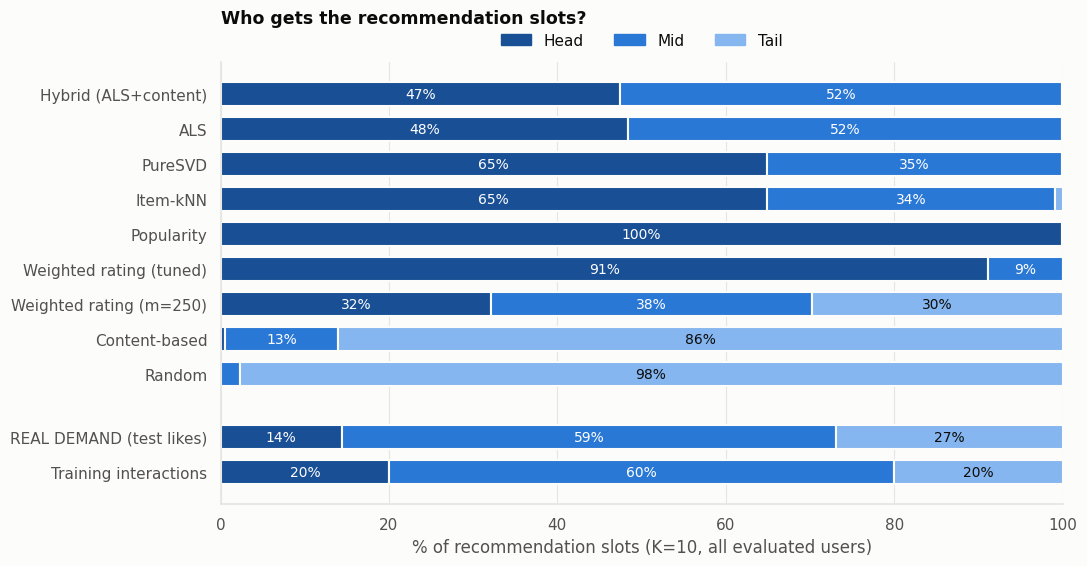

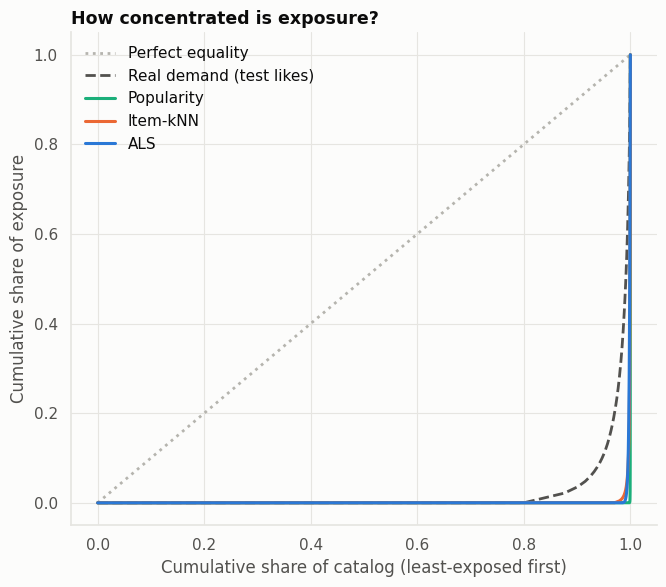

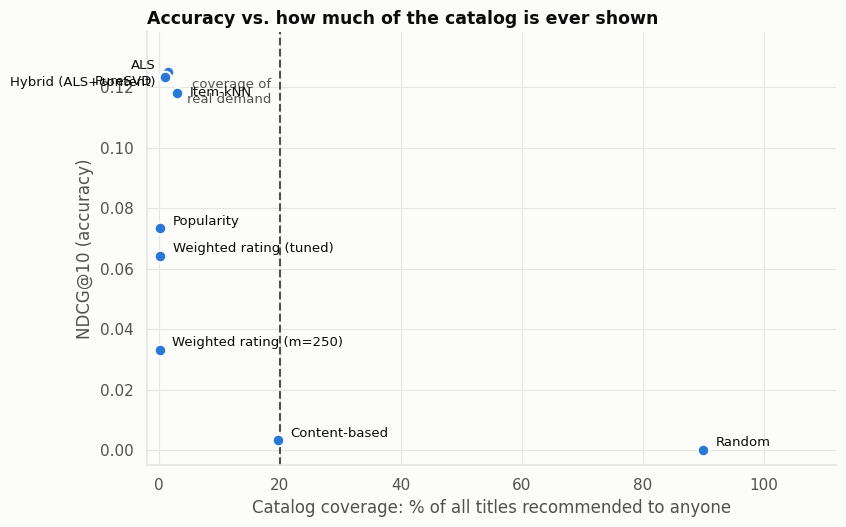

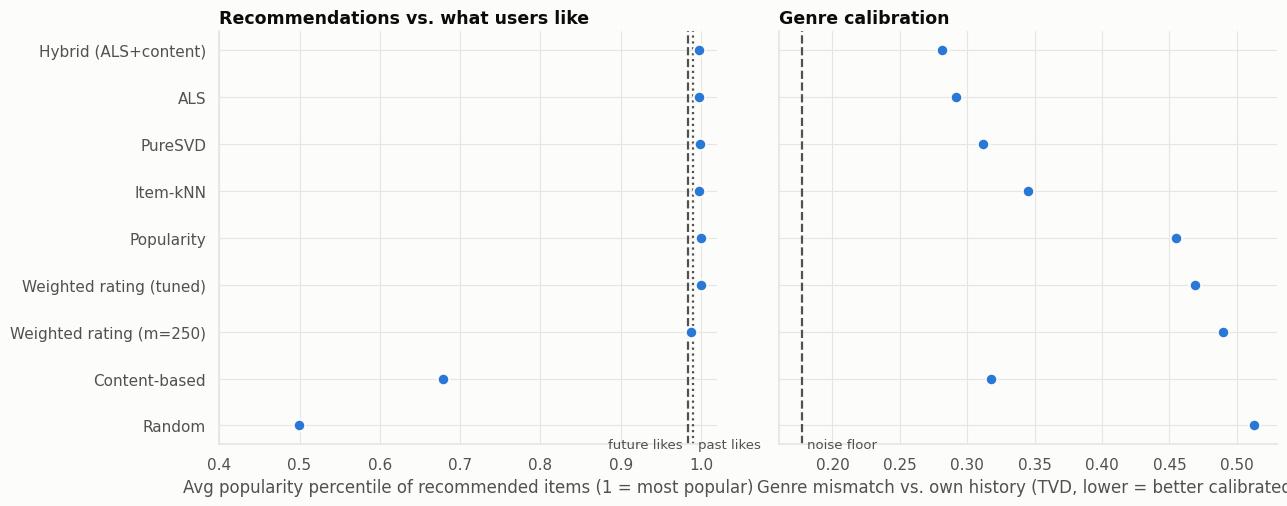

In [20]:
# Plot the main audit results


SURF, INK, INK2, GRID, GREY = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1", "#b5b4ae"
TIER = {"head": "#184f95", "mid": "#2a78d6", "tail": "#86b6ef"}
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
                     "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.edgecolor": GRID, "font.size": 11, "axes.titleweight": "bold", "axes.titlesize": 12.5})

def clean(ax, grid="x"):
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    ax.grid(axis=grid, color=GRID, lw=0.8); ax.set_axisbelow(True)


rows = [(SHORT[n], audit.loc[SHORT[n], ["head_%", "mid_%", "tail_%"]].values) for n in ORDER]
rows += [("REAL DEMAND (test likes)", 100 * demand_share), ("Training interactions", 100 * train_share)]
fig, ax = plt.subplots(figsize=(11, 5.8))
ypos = list(range(len(ORDER))) + [len(ORDER) + 0.8, len(ORDER) + 1.8]
for y, (lab, v) in zip(ypos, rows):
    left = 0
    for g, val, col in zip(GRP_NAMES, v, [TIER["head"], TIER["mid"], TIER["tail"]]):
        ax.barh(y, val, left=left, color=col, edgecolor=SURF, linewidth=1.5, height=0.7)
        if val >= 7: ax.text(left + val / 2, y, f"{val:.0f}%", ha="center", va="center", fontsize=10,
                             color="white" if g != "tail" else INK)
        left += val
ax.set_yticks(ypos); ax.set_yticklabels([r[0] for r in rows]); ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xlabel("% of recommendation slots (K=10, all evaluated users)"); clean(ax)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=TIER[g]) for g in GRP_NAMES], labels=["Head", "Mid", "Tail"],
          ncol=3, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.set_title("Who gets the recommendation slots?", loc="left", pad=28); plt.tight_layout(); plt.show()


def lorenz(expo):
    e = np.sort(expo.astype(float)); c = np.cumsum(e) / e.sum(); return np.r_[0, np.arange(1, len(e) + 1) / len(e)], np.r_[0, c]
pick = [("Popularity", C3), ("Item-kNN", C2), ("ALS", C1)]
fig, ax = plt.subplots(figsize=(6.8, 6))
ax.plot([0, 1], [0, 1], ls=":", color=GREY, lw=2, label="Perfect equality")
x, y = lorenz(demand_expo); ax.plot(x, y, ls="--", color=INK2, lw=2, label="Real demand (test likes)")
for short, col in pick:
    full = next(n for n in ORDER if SHORT[n] == short)
    x, y = lorenz(np.bincount(RECS_TEST[full].ravel(), minlength=N_ITEMS)); ax.plot(x, y, color=col, lw=2.2, label=short)
ax.set(xlabel="Cumulative share of catalog (least-exposed first)", ylabel="Cumulative share of exposure")
ax.set_title("How concentrated is exposure?", loc="left")
clean(ax, "both"); ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()


fig, ax = plt.subplots(figsize=(8.6, 5.4))
ax.scatter(audit["coverage_%"], audit["NDCG@10"], s=70, color=C1, edgecolor=SURF, linewidth=1.5, zorder=3)
ax.axvline(bench["coverage_%"], color=INK2, ls="--", lw=1.5)
ax.text(bench["coverage_%"] - 1.5, audit["NDCG@10"].max() * 0.98, "coverage of\nreal demand", ha="right", va="top", color=INK2, fontsize=9.5)

place = {"ALS": ("L", 5), "Hybrid (ALS+content)": ("L", -9), "PureSVD": ("L", -3), "Item-kNN": ("R", 0)}
for name, r in audit.iterrows():
    side, dy = place.get(name, ("R", 5))
    ax.annotate(name, (r["coverage_%"], r["NDCG@10"]), xytext=(-9 if side == "L" else 9, dy), textcoords="offset points",
                ha="right" if side == "L" else "left", va="center", fontsize=9.5, color=INK)
ax.set(xlabel="Catalog coverage: % of all titles recommended to anyone", ylabel="NDCG@10 (accuracy)")
ax.set_title("Accuracy vs. how much of the catalog is ever shown", loc="left")
ax.set_xlim(-2, 112); ax.set_ylim(-0.005, audit["NDCG@10"].max() * 1.1); clean(ax, "both"); plt.tight_layout(); plt.show()


fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
ys = np.arange(len(ORDER))
ax = axes[0]; ax.scatter(audit["ARP_pct"], ys, s=70, color=C1, edgecolor=SURF, linewidth=1.5, zorder=3)
for val, lab, ls, ha, dx in [(np.nanmean(hist_pop), "past likes", ":", "left", 0.006), (np.nanmean(demand_pop), "future likes", "--", "right", -0.006)]:
    ax.axvline(val, color=INK2, ls=ls, lw=1.6); ax.text(val + dx, len(ORDER) - 0.45, lab, ha=ha, va="bottom", color=INK2, fontsize=9.5)
ax.set_yticks(ys); ax.set_yticklabels(audit.index); ax.invert_yaxis(); ax.set_xlim(0.4, 1.02)
ax.set_xlabel("Avg popularity percentile of recommended items (1 = most popular)"); ax.set_title("Recommendations vs. what users like", loc="left"); clean(ax, "both")
ax = axes[1]; ax.scatter(audit["genre_TVD"], ys, s=70, color=C1, edgecolor=SURF, linewidth=1.5, zorder=3)
ax.axvline(TVD_FLOOR, color=INK2, ls="--", lw=1.6); ax.text(TVD_FLOOR + 0.004, len(ORDER) - 0.45, "noise floor", ha="left", va="bottom", color=INK2, fontsize=9.5)
ax.set_xlabel("Genre mismatch vs. own history (TVD, lower = better calibrated)"); ax.set_title("Genre calibration", loc="left"); clean(ax, "both")
plt.tight_layout(); plt.show()


Group definitions (measured on TRAIN history only):
  niche / mainstream = lowest / highest third by avg popularity of past likes, WITHIN each activity tercile (activity-balanced)
  light / heavy = fewest / most training ratings (<= 35 / >= 92)
Real demand - share of future likes that are head titles:
  niche taste: 18.0%  |  mainstream taste: 24.5%
  light users: 30.0%  |  heavy users: 12.6%


NDCG@10                                           \
comparison                    Taste                     Activity               
group                   niche taste mainstream taste light users heavy users   
model                                                                          
Hybrid (ALS+content)          0.115            0.136       0.100       0.174   
ALS                           0.115            0.135       0.099       0.175   
PureSVD                       0.111            0.135       0.098       0.173   
Item-kNN                      0.104            0.132       0.100       0.159   
Popularity                    0.069            0.074       0.058       0.104   
Weighted rating (tuned)       0.067            0.060       0.056       0.089   
Weighted rating (m=250)       0.040            0.026       0.027       0.049   
Content-based                 0.003            0.003       0.003       0.004   
Random                        0.000            0.000       0.000       0.000   

                        NDCG_vs_pop_x                               \
comparison                      Taste                     Activity   
group                     niche taste mainstream taste light users   
model                                                                
Hybrid (ALS+content)            1.659            1.846       1.716   
ALS                             1.657            1.831       1.699   
PureSVD                         1.595            1.835       1.691   
Item-kNN                        1.504            1.793       1.730   
Popularity                      1.000            1.000       1.000   
Weighted rating (tuned)         0.973            0.811       0.962   
Weighted rating (m=250)         0.583            0.356       0.459   
Content-based                   0.044            0.045       0.048   
Random                          0.003            0.002       0.001   

                                    head_slots_%                               \
comparison                                 Taste                     Activity   
group                   heavy users  niche taste mainstream taste light users   
model                                                                           
Hybrid (ALS+content)          1.673       38.810           56.789      53.948   
ALS                           1.678       39.947           57.504      54.707   
PureSVD                       1.657       58.564           70.658      71.084   
Item-kNN                      1.530       51.773           76.411      61.455   
Popularity                    1.000       99.794           99.936     100.000   
Weighted rating (tuned)       0.857       93.341           88.554      97.611   
Weighted rating (m=250)       0.474       34.277           29.858      36.909   
Content-based                 0.035        0.459            0.607       1.054   
Random                        0.003        0.083            0.081       0.097   

                                     
comparison                           
group                   heavy users  
model                                
Hybrid (ALS+content)         36.910  
ALS                          38.152  
PureSVD                      54.420  
Item-kNN                     66.178  
Popularity                   99.667  
Weighted rating (tuned)      82.215  
Weighted rating (m=250)      26.090  
Content-based                 0.126  
Random                        0.054

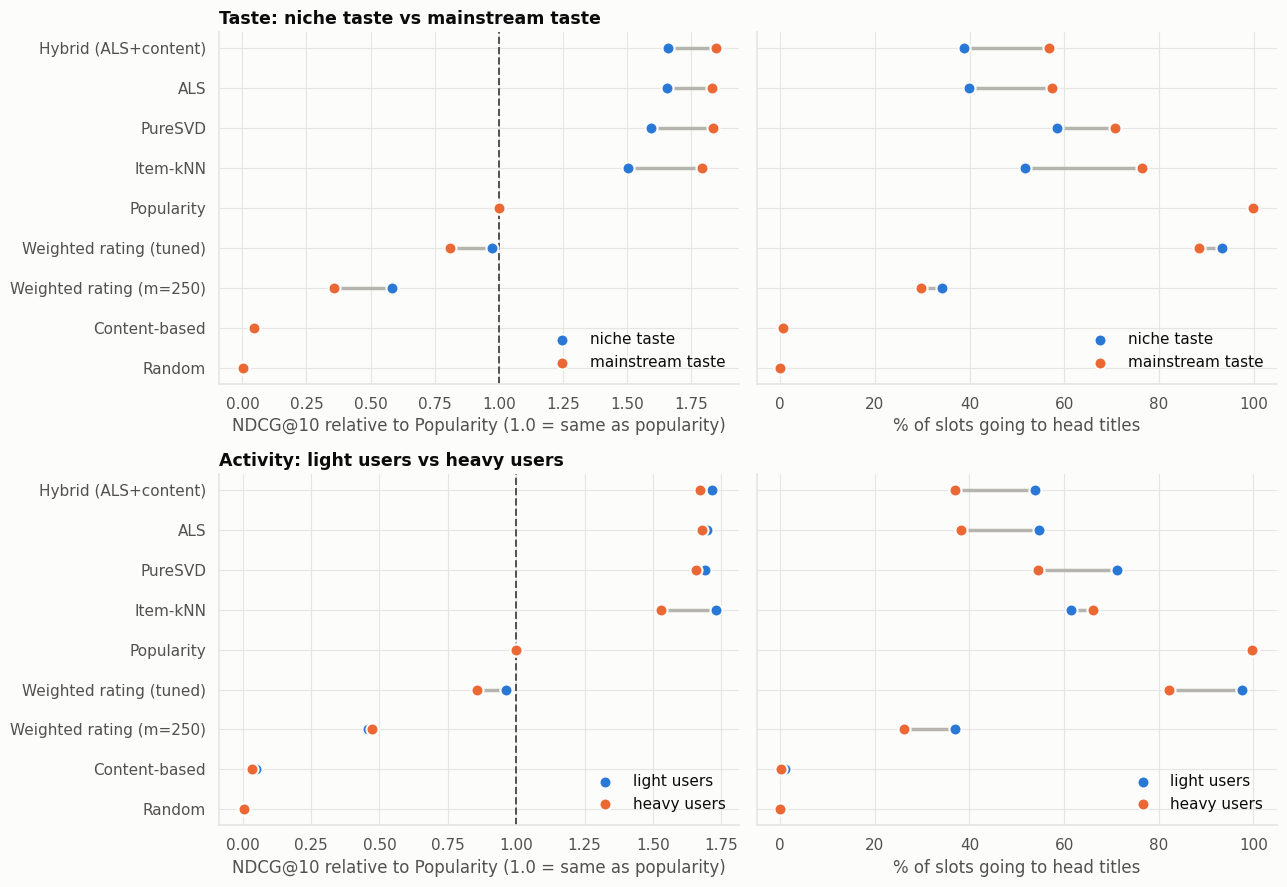

Share of recommendation slots by release era (%):


,pre-2000,2000-2009,2010+ (recent)
Hybrid (ALS+content),65.8,23.7,10.5
ALS,65.9,23.7,10.4
PureSVD,68.7,22.7,8.6
Item-kNN,69.4,23.5,7.2
Popularity,82.6,16.4,1.1
Weighted rating (tuned),80.7,13.9,5.4
Weighted rating (m=250),57.0,22.6,20.4
Content-based,51.4,33.9,14.7
Random,41.2,17.7,41.2
Catalog (all titles),41.3,17.7,41.1


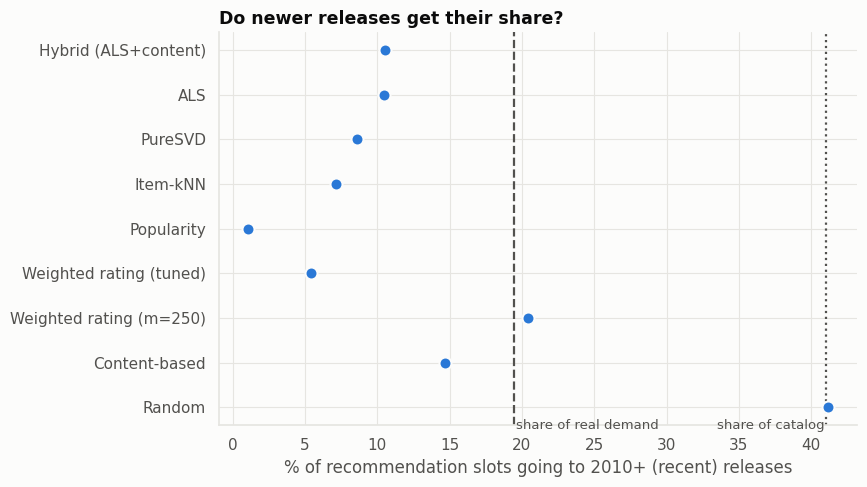

head_%              tail_%            
cutoff (head/tail share)  10/10 20/20  30/30  10/10 20/20 30/30
model                                                          
REAL DEMAND                 6.5  14.4   23.2   14.7  26.9  38.1
Hybrid (ALS+content)       21.2  47.4   69.5    0.0   0.1   0.4
ALS                        21.9  48.4   70.7    0.0   0.1   0.3
PureSVD                    33.9  64.9   84.5    0.0   0.0   0.1
Item-kNN                   37.6  64.8   79.6    0.3   0.9   2.1
Popularity                 97.8  99.9  100.0    0.0   0.0   0.0
Weighted rating (tuned)    70.4  91.1   99.1    0.0   0.0   0.0
Weighted rating (m=250)    23.5  32.2   40.4    0.0  29.8  29.8
Content-based               0.4   0.6    1.3   78.5  86.0  90.4
Random                      0.0   0.1    0.2   95.7  97.8  98.6

In [21]:
# Break results down by user and item groups


def terciles(v):
    v = np.where(np.isnan(v), np.nanmedian(v), v)
    return pd.qcut(pd.Series(v).rank(method="first"), 3, labels=["low", "mid", "high"]).to_numpy().astype(str)

n_train_ratings = np.asarray((X_train_ratings[rows_idx] > 0).sum(axis=1)).ravel()
activity = terciles(n_train_ratings)


hp = pd.Series(np.where(np.isnan(hist_pop), np.nanmedian(hist_pop), hist_pop))
taste = hp.groupby(activity).transform(lambda s: pd.Series(terciles(s.values), index=s.index)).to_numpy()
GROUPS = {"Taste": ("niche taste", "mainstream taste", taste),
          "Activity": ("light users", "heavy users", activity)}
print("Group definitions (measured on TRAIN history only):")
print("  niche / mainstream = lowest / highest third by avg popularity of past likes, WITHIN each activity tercile (activity-balanced)")
print(f"  light / heavy = fewest / most training ratings (<= {np.percentile(n_train_ratings, 33.3):.0f} / >= {np.percentile(n_train_ratings, 66.7):.0f})")


dem_head_u = np.asarray(T @ (GRP == 0).astype(float)).ravel() / np.asarray(T.sum(axis=1)).ravel()
print("Real demand - share of future likes that are head titles:")
for gname, (lo_lab, hi_lab, t) in GROUPS.items():
    print(f"  {lo_lab}: {100*dem_head_u[t == 'low'].mean():.1f}%  |  {hi_lab}: {100*dem_head_u[t == 'high'].mean():.1f}%")

rows = []
for n in ORDER:
    recs = RECS_TEST[n]; nd = PER_USER_TEST[n].ndcg.values
    head_u = (GRP[recs] == 0).mean(axis=1); tail_u = (GRP[recs] == 2).mean(axis=1); gap_u = pop_pct[recs].mean(axis=1) - demand_pop
    for gname, (lo_lab, hi_lab, t) in GROUPS.items():
        for lab, mask in [(lo_lab, t == "low"), (hi_lab, t == "high")]:
            rows.append({"model": SHORT[n], "comparison": gname, "group": lab, "n_users": int(mask.sum()),
                         "NDCG@10": nd[mask].mean(), "head_slots_%": 100 * head_u[mask].mean(),
                         "tail_slots_%": 100 * tail_u[mask].mean(), "pop_gap": gap_u[mask].mean()})
grp = pd.DataFrame(rows)
pop_nd = grp[grp.model == "Popularity"].set_index(["comparison", "group"])["NDCG@10"]
grp["NDCG_vs_pop_x"] = [r["NDCG@10"] / pop_nd[(r["comparison"], r["group"])] for _, r in grp.iterrows()]
display(grp.pivot_table(index="model", columns=["comparison", "group"], values=["NDCG@10", "NDCG_vs_pop_x", "head_slots_%"], sort=False).round(3))


fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
ys = np.arange(len(ORDER)); names = [SHORT[n] for n in ORDER]
for r, (gname, (lo_lab, hi_lab, _)) in enumerate(GROUPS.items()):
    for c, (metric, xl) in enumerate([("NDCG_vs_pop_x", "NDCG@10 relative to Popularity (1.0 = same as popularity)"), ("head_slots_%", "% of slots going to head titles")]):
        ax = axes[r, c]; d = grp[grp.comparison == gname]
        a = d[d.group == lo_lab].set_index("model").loc[names, metric].values
        b = d[d.group == hi_lab].set_index("model").loc[names, metric].values
        ax.hlines(ys, a, b, color=GREY, lw=2.5, zorder=1)
        ax.scatter(a, ys, s=75, color=C1, edgecolor=SURF, linewidth=1.5, zorder=3, label=lo_lab)
        ax.scatter(b, ys, s=75, color=C2, edgecolor=SURF, linewidth=1.5, zorder=3, label=hi_lab)
        ax.set_yticks(ys); ax.set_yticklabels(names); ax.set_xlabel(xl); clean(ax, "both")
        if metric == "NDCG_vs_pop_x": ax.axvline(1.0, color=INK2, ls="--", lw=1.4)
        ax.legend(frameon=False, loc="lower right")
        if c == 0: ax.set_title(f"{gname}: {lo_lab} vs {hi_lab}", loc="left")
axes[0, 0].invert_yaxis(); plt.tight_layout(); plt.show()


age_slots = {SHORT[n]: np.bincount(AGE_BAND[RECS_TEST[n].ravel()], minlength=3) / RECS_TEST[n].size for n in ORDER}
age_tbl = pd.DataFrame(age_slots, index=AGE_NAMES).T * 100
age_tbl.loc["Catalog (all titles)"] = np.bincount(AGE_BAND, minlength=3) / N_ITEMS * 100
age_tbl.loc["REAL DEMAND (test likes)"] = np.bincount(AGE_BAND[T.indices], minlength=3) / T.nnz * 100
print("Share of recommendation slots by release era (%):"); display(age_tbl.round(1))


fig, ax = plt.subplots(figsize=(8.8, 5)); ys = np.arange(len(ORDER)); rec_share = age_tbl.loc[names, AGE_NAMES[2]].values
ax.scatter(rec_share, ys, s=75, color=C1, edgecolor=SURF, linewidth=1.5, zorder=3)
cat_v, dem_v = age_tbl.loc["Catalog (all titles)", AGE_NAMES[2]], age_tbl.loc["REAL DEMAND (test likes)", AGE_NAMES[2]]
refs = [(cat_v, "share of catalog", ":", "right", -0.15), (dem_v, "share of real demand", "--", "left", 0.15)]
if abs(cat_v - dem_v) < 1: refs = [((cat_v + dem_v) / 2, "catalog share ≈ real-demand share", "--", "left", 0.15)]
for val, lab, ls, ha, dx in refs:
    ax.axvline(val, color=INK2, ls=ls, lw=1.6); ax.text(val + dx, len(ORDER) - 0.45, lab, ha=ha, va="bottom", color=INK2, fontsize=9.5)
ax.set_yticks(ys); ax.set_yticklabels(names); ax.invert_yaxis(); clean(ax, "both")
ax.set_xlabel(f"% of recommendation slots going to {AGE_NAMES[2]} releases"); ax.set_title("Do newer releases get their share?", loc="left")
plt.tight_layout(); plt.show()


train_pop_series = pop_train
rows = []
for hs, ts in [(0.10, 0.10), (0.20, 0.20), (0.30, 0.30)]:
    g_alt = define_popularity_groups(train_pop_series, hs, ts)
    dem = np.bincount(g_alt[T.indices], minlength=3) / T.nnz
    rows.append({"cutoff (head/tail share)": f"{int(hs*100)}/{int(ts*100)}", "model": "REAL DEMAND", "head_%": 100*dem[0], "tail_%": 100*dem[2],
                 "n_head_items": int((g_alt == 0).sum()), "n_tail_items": int((g_alt == 2).sum())})
    for n in ORDER:
        sh = np.bincount(g_alt[RECS_TEST[n].ravel()], minlength=3) / RECS_TEST[n].size
        rows.append({"cutoff (head/tail share)": f"{int(hs*100)}/{int(ts*100)}", "model": SHORT[n], "head_%": 100*sh[0], "tail_%": 100*sh[2]})
sens = pd.DataFrame(rows)
display(sens.pivot_table(index="model", columns="cutoff (head/tail share)", values=["head_%", "tail_%"], sort=False).round(1))


In [22]:
# Set up the mitigation methods


M_POOL  = 100
POP_PEN = np.log1p(train_cnt) / np.log1p(train_cnt.max())

def top_pool(score_fn, users, X_seen, M=M_POOL, batch=500, allowed=None):
    """top-m unseen items per user with their model scores (best first). allowed = optional bool mask of titles that may be recommended"""
    users = np.asarray(users); n = len(users)
    idx = np.empty((n, M), np.int32); sc = np.empty((n, M), np.float32)
    for s in range(0, n, batch):
        b = users[s:s + batch]
        scores = np.array(score_fn(b), dtype=np.float32)
        r, c = X_seen[b].nonzero(); scores[r, c] = -np.inf
        if allowed is not None: scores[:, ~allowed] = -np.inf
        part = np.argpartition(-scores, M, axis=1)[:, :M]; ps = np.take_along_axis(scores, part, 1)
        o = np.argsort(-ps, axis=1)
        idx[s:s + batch] = np.take_along_axis(part, o, 1); sc[s:s + batch] = np.take_along_axis(ps, o, 1)
    return idx, sc

def make_ctx(model, users, truth, X_seen, allowed=None):
    """everything a re-ranker needs for one split (val or test)"""
    idx, sc = top_pool(model.score, users, X_seen, allowed=allowed)
    p = np.asarray(X_train_pos[users] @ Gn); s = p.sum(axis=1, keepdims=True)
    p = np.divide(p, s, out=np.zeros_like(p), where=s > 0)
    return {"users": np.asarray(users), "truth": truth, "idx": idx, "sc": sc, "p": p, "seen": X_seen,
            "demand_pop": demand_pop[np.searchsorted(TEST_USERS, users)]}


def rerank_pop(ctx, lam, K=TOPK):
    """adjusted score = z(model score within the pool) - lam * log popularity. lam=0 gives back the base list"""
    sc = ctx["sc"]; z = (sc - sc.mean(axis=1, keepdims=True)) / (sc.std(axis=1, keepdims=True) + 1e-9)
    adj = z - lam * POP_PEN[ctx["idx"]]
    return np.take_along_axis(ctx["idx"], np.argsort(-adj, axis=1)[:, :K], 1)


def rerank_calibrated(ctx, lam, K=TOPK, alpha=0.01, Gmat=None, chunk=4000):
    """build each list greedily, trading relevance against kl(user's genre mix || list's genre mix). lam=0 gives the base list.
    Gmat = per-title genre shares (defaults to the full catalog, the simulation passes its own smaller one). users go in chunks to bound memory"""
    Gm = Gn if Gmat is None else Gmat
    idx_all, sc_all, p_all = ctx["idx"], ctx["sc"], ctx["p"]; out = np.empty((len(idx_all), K), np.int32)
    for a in range(0, len(idx_all), chunk):
        idx, sc, p = idx_all[a:a + chunk], sc_all[a:a + chunk], p_all[a:a + chunk]; n, M = idx.shape
        rel = (sc - sc.min(axis=1, keepdims=True)) / (sc.max(axis=1, keepdims=True) - sc.min(axis=1, keepdims=True) + 1e-9)
        CG = Gm[idx]
        logp = np.log(np.where(p > 0, p, 1.0)); S = np.zeros_like(p)
        chosen = np.zeros((n, M), bool); r = np.arange(n)
        for k in range(K):
            q = (S[:, None, :] + CG) / (k + 1)
            qs = np.maximum((1 - alpha) * q + alpha * p[:, None, :], 1e-12)
            kl = (p[:, None, :] * (logp[:, None, :] - np.log(qs))).sum(axis=-1)
            obj = (1 - lam) * rel - lam * kl; obj[chosen] = -np.inf
            j = obj.argmax(axis=1); out[a:a + n, k] = idx[r, j]; chosen[r, j] = True; S += CG[r, j]
    return out





def intra_list_diversity(recs, Gmat=None):
    """1 - average pairwise genre cosine similarity inside each list (0 = identical, 1 = no shared genre)"""
    V = (G if Gmat is None else Gmat)[recs]; V = V / np.linalg.norm(V, axis=2, keepdims=True); K = recs.shape[1]
    sim = np.einsum("nkg,njg->nkj", V, V)
    return float((1 - (sim.sum(axis=(1, 2)) - K) / (K * (K - 1))).mean())

def eval_point(recs, ctx, is_test=False, items=None):
    """one operating point. items = optional array of title indices that make up the 'catalog' for exposure metrics (the app uses this)"""
    pu = evaluate_recs(recs, ctx["users"], ctx["truth"]); expo = np.bincount(recs.ravel(), minlength=N_ITEMS)
    if items is not None: expo = expo[items]
    has_p = ctx["p"].sum(axis=1) > 0
    tvd = (0.5 * np.abs(ctx["p"] - Gn[recs].mean(axis=1)).sum(axis=1))[has_p].mean()
    out = {"NDCG@10": pu.ndcg.mean(), "head_%": 100 * (GRP[recs] == 0).mean(), "tail_%": 100 * (GRP[recs] == 2).mean(),
           "coverage_%": 100 * (expo > 0).mean(), "gini": gini(expo), "effective_titles": effective_titles(expo),
           "ILD": intra_list_diversity(recs), "genre_TVD": tvd}
    out["pop_gap"] = (pop_pct[recs].mean(axis=1) - ctx["demand_pop"]).mean() if is_test else np.nan
    return out, pu.ndcg.values

def sweep(recs_fn, grid, ctx, is_test, label, base_ndcg=None):
    """recs_fn(ctx, param) -> recs. first grid value = off. rel_NDCG_% is relative to base_ndcg (default is the first row)"""
    rows, per_user, recs_store = [], {}, {}
    for v in grid:
        recs = recs_fn(ctx, v); m, nd = eval_point(recs, ctx, is_test)
        rows.append({"method": label, "param": v, **m}); per_user[v] = nd; recs_store[v] = recs
    df = pd.DataFrame(rows); df["rel_NDCG_%"] = 100 * df["NDCG@10"] / (base_ndcg if base_ndcg is not None else df["NDCG@10"].iloc[0])
    return df, per_user, recs_store


In [23]:
# Run the mitigation experiments


POP_GRID = [0, 1, 3, 8, 12] if FAST else [0, 0.5, 1, 2, 3, 5, 8, 12, 20]
CAL_GRID = [0, 0.4, 0.8, 0.95]  if FAST else [0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95]
GAM_GRID = [0, 0.5, 1.0]   if FAST else [0, 0.25, 0.5, 0.75, 1.0]

t0 = time.time()
als_base = als_final
ctx_val  = make_ctx(als_base, VAL_USERS,  val_rel,  X_seen_val)
ctx_test = make_ctx(als_base, TEST_USERS, test_rel, X_seen_test)
same = np.array_equal(rerank_pop(ctx_test, 0.0), RECS_TEST[next(n for n in ORDER if SHORT[n] == "ALS")])
print(f"lambda=0 reproduces the Stage 5 ALS lists exactly: {same}")


wmodels = {0: als_base}
for g in GAM_GRID:
    if g == 0: continue
    wmodels[g] = ImplicitALS(gamma=g, iters=10, **als_p).fit(X_train_ratings, X_train_pos); print(f"  weighted ALS gamma={g} trained ({time.time() - t0:.0f}s)")
recs_weighted = lambda ctx, g: topk_recommend(wmodels[g].score, ctx["users"], ctx["seen"])

def run_sweeps(ctx, is_test):
    return {"Popularity penalty":    sweep(rerank_pop,        POP_GRID, ctx, is_test, "Popularity penalty"),
            "Calibrated re-rank":    sweep(rerank_calibrated, CAL_GRID, ctx, is_test, "Calibrated re-rank"),
            "Inverse-pop training":  sweep(recs_weighted,     GAM_GRID, ctx, is_test, "Inverse-pop training")}
SW_VAL, SW_TEST = run_sweeps(ctx_val, False), run_sweeps(ctx_test, True)


OBJ = {"Popularity penalty":               ("effective_titles", True),
       "Inverse-pop training":             ("effective_titles", True),
       "Calibrated re-rank":               ("genre_TVD", False),
       "Weighted training + calibrated":   ("genre_TVD", False)}
def pick(df_val, budget, method):
    obj, maximize = OBJ[method]
    ok = df_val[df_val["rel_NDCG_%"] >= 100 * (1 - budget)]
    if ok.empty:
        best = df_val.loc[df_val["rel_NDCG_%"].idxmax(), "param"]
        print(f"  note: '{method}' cannot meet a {budget:.0%} budget on validation; using its most accurate setting ({best})")
        return best
    return ok.loc[ok[obj].idxmax() if maximize else ok[obj].idxmin(), "param"]


g_star = pick(SW_VAL["Inverse-pop training"][0], 0.05, "Inverse-pop training")
print(f"Combined method uses inverse-popularity training with gamma={g_star} (picked on validation, 5% budget)")
ctx_val_w  = make_ctx(wmodels[g_star], VAL_USERS,  val_rel,  X_seen_val)
ctx_test_w = make_ctx(wmodels[g_star], TEST_USERS, test_rel, X_seen_test)
CM = "Weighted training + calibrated"
SW_VAL[CM]  = sweep(rerank_calibrated, CAL_GRID, ctx_val_w,  False, CM, base_ndcg=SW_VAL["Calibrated re-rank"][0]["NDCG@10"].iloc[0])
SW_TEST[CM] = sweep(rerank_calibrated, CAL_GRID, ctx_test_w, True,  CM, base_ndcg=SW_TEST["Calibrated re-rank"][0]["NDCG@10"].iloc[0])
print(f"all sweeps done in {time.time() - t0:.0f}s")

cols = ["param", "NDCG@10", "rel_NDCG_%", "head_%", "tail_%", "coverage_%", "gini", "effective_titles", "ILD", "genre_TVD", "pop_gap"]
for m, (df, _, _) in SW_TEST.items():
    print(f"\n--- {m} (TEST users; param = lambda or gamma; rel_NDCG_% is vs. the original ALS) ---"); display(df[cols].round(3))


BUDGETS = [0.02, 0.05, 0.10]
rows = []
for m in SW_VAL:
    dv, dt = SW_VAL[m][0], SW_TEST[m][0]
    for b in BUDGETS:
        lam = pick(dv, b, m); r = dt[dt.param == lam].iloc[0]
        diff = SW_TEST[m][1][lam] - SW_TEST["Calibrated re-rank"][1][0]
        rows.append({"method": m, "budget": f"{int(b*100)}%", "param": lam, "rel_NDCG_%": r["rel_NDCG_%"],
                     "dNDCG (95% CI)": f"{diff.mean():+.4f} ± {1.96*diff.std()/np.sqrt(len(diff)):.4f}",
                     "tail_%": r["tail_%"], "coverage_%": r["coverage_%"], "effective_titles": r["effective_titles"],
                     "ILD": r["ILD"], "genre_TVD": r["genre_TVD"]})
op_tbl = pd.DataFrame(rows)
print("\nOperating points: parameter picked on VALIDATION inside each accuracy budget, results reported on TEST")
display(op_tbl.round(3))


lambda=0 reproduces the Stage 5 ALS lists exactly: True
  weighted ALS gamma=0.25 trained (127s)
  weighted ALS gamma=0.5 trained (209s)
  weighted ALS gamma=0.75 trained (289s)
  weighted ALS gamma=1.0 trained (371s)
Combined method uses inverse-popularity training with gamma=0.25 (picked on validation, 5% budget)
all sweeps done in 839s

--- Popularity penalty (TEST users; param = lambda or gamma; rel_NDCG_% is vs. the original ALS) ---


,param,NDCG@10,rel_NDCG_%,head_%,tail_%,coverage_%,gini,effective_titles,ILD,genre_TVD,pop_gap
0,0.0,0.125,100.000,48.419,0.068,1.435,0.996,419.386,0.664,0.292,0.014
1,0.5,0.125,99.852,47.672,0.072,1.450,0.996,427.127,0.662,0.292,0.014
2,1.0,0.125,99.885,46.913,0.074,1.466,0.996,435.179,0.661,0.291,0.014
3,2.0,0.124,99.611,45.353,0.082,1.505,0.996,452.414,0.659,0.291,0.014
4,3.0,0.124,99.333,43.828,0.091,1.549,0.996,470.211,0.657,0.291,0.014
5,5.0,0.123,98.754,40.660,0.120,1.641,0.996,509.139,0.652,0.290,0.014
6,8.0,0.122,97.673,35.720,0.237,1.844,0.995,581.746,0.643,0.291,0.013
7,12.0,0.119,94.961,28.619,0.991,2.142,0.994,728.672,0.627,0.294,0.012
8,20.0,0.103,82.290,14.370,4.172,2.589,0.991,1113.262,0.584,0.315,0.008



--- Calibrated re-rank (TEST users; param = lambda or gamma; rel_NDCG_% is vs. the original ALS) ---


,param,NDCG@10,rel_NDCG_%,head_%,tail_%,coverage_%,gini,effective_titles,ILD,genre_TVD,pop_gap
0,0.00,0.125,100.000,48.419,0.068,1.435,0.996,419.386,0.664,0.292,0.014
1,0.20,0.125,100.216,48.446,0.066,1.443,0.996,419.559,0.674,0.274,0.014
2,0.40,0.122,97.381,48.046,0.072,1.483,0.996,424.672,0.681,0.251,0.014
3,0.60,0.114,91.217,46.470,0.103,1.555,0.996,438.392,0.682,0.222,0.014
4,0.80,0.103,82.145,42.904,0.174,1.684,0.996,469.964,0.680,0.179,0.014
5,0.90,0.094,75.045,38.848,0.250,1.839,0.996,507.285,0.669,0.143,0.014
6,0.95,0.085,68.383,34.550,0.344,1.974,0.995,547.166,0.655,0.116,0.013



--- Inverse-pop training (TEST users; param = lambda or gamma; rel_NDCG_% is vs. the original ALS) ---


,param,NDCG@10,rel_NDCG_%,head_%,tail_%,coverage_%,gini,effective_titles,ILD,genre_TVD,pop_gap
0,0.00,0.125,100.000,48.419,0.068,1.435,0.996,419.386,0.664,0.292,0.014
1,0.25,0.128,102.820,50.060,0.206,1.895,0.996,439.393,0.656,0.292,0.014
2,0.50,0.130,104.359,57.730,0.550,2.273,0.997,362.429,0.652,0.302,0.014
3,0.75,0.127,101.555,70.564,0.486,1.957,0.998,227.544,0.664,0.323,0.015
4,1.00,0.122,97.946,75.996,0.480,1.828,0.998,181.388,0.673,0.333,0.014



--- Weighted training + calibrated (TEST users; param = lambda or gamma; rel_NDCG_% is vs. the original ALS) ---


,param,NDCG@10,rel_NDCG_%,head_%,tail_%,coverage_%,gini,effective_titles,ILD,genre_TVD,pop_gap
0,0.00,0.128,102.820,50.060,0.206,1.895,0.996,439.393,0.656,0.292,0.014
1,0.20,0.128,102.613,50.048,0.206,1.900,0.996,439.853,0.668,0.274,0.014
2,0.40,0.125,99.952,49.612,0.222,1.943,0.996,445.178,0.675,0.251,0.014
3,0.60,0.117,93.524,48.048,0.306,2.012,0.996,459.101,0.678,0.221,0.014
4,0.80,0.106,84.599,44.250,0.514,2.152,0.996,496.640,0.677,0.179,0.014
5,0.90,0.096,76.923,39.908,0.737,2.303,0.995,543.484,0.668,0.143,0.013
6,0.95,0.088,70.507,35.446,0.939,2.484,0.995,593.085,0.654,0.116,0.013



Operating points: parameter picked on VALIDATION inside each accuracy budget, results reported on TEST


,method,budget,param,rel_NDCG_%,dNDCG (95% CI),tail_%,coverage_%,effective_titles,ILD,genre_TVD
0,Popularity penalty,2%,8.00,97.673,-0.0029 ± 0.0007,0.237,1.844,581.746,0.643,0.291
1,Popularity penalty,5%,12.00,94.961,-0.0063 ± 0.0010,0.991,2.142,728.672,0.627,0.294
2,Popularity penalty,10%,12.00,94.961,-0.0063 ± 0.0010,0.991,2.142,728.672,0.627,0.294
3,Calibrated re-rank,2%,0.20,100.216,+0.0003 ± 0.0006,0.066,1.443,419.559,0.674,0.274
4,Calibrated re-rank,5%,0.40,97.381,-0.0033 ± 0.0009,0.072,1.483,424.672,0.681,0.251
5,Calibrated re-rank,10%,0.40,97.381,-0.0033 ± 0.0009,0.072,1.483,424.672,0.681,0.251
6,Inverse-pop training,2%,0.25,102.820,+0.0035 ± 0.0010,0.206,1.895,439.393,0.656,0.292
7,Inverse-pop training,5%,0.25,102.820,+0.0035 ± 0.0010,0.206,1.895,439.393,0.656,0.292
8,Inverse-pop training,10%,0.25,102.820,+0.0035 ± 0.0010,0.206,1.895,439.393,0.656,0.292
9,Weighted training + calibrated,2%,0.40,99.952,-0.0001 ± 0.0012,0.222,1.943,445.178,0.675,0.251


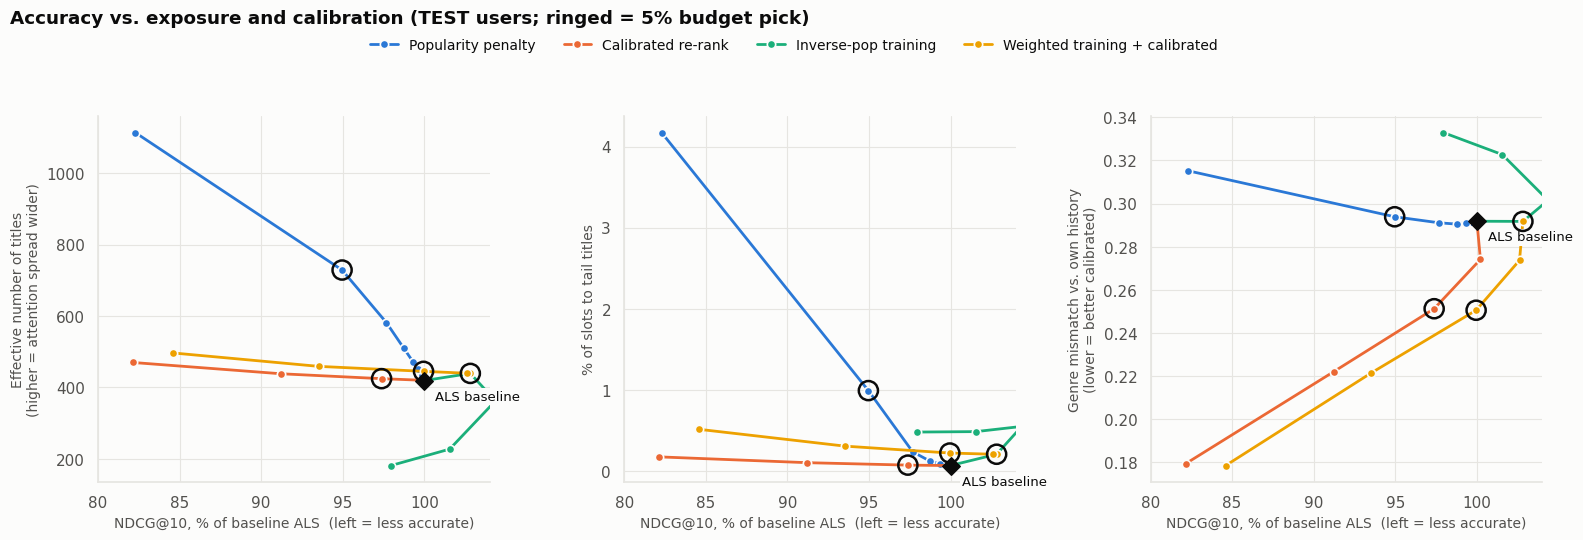

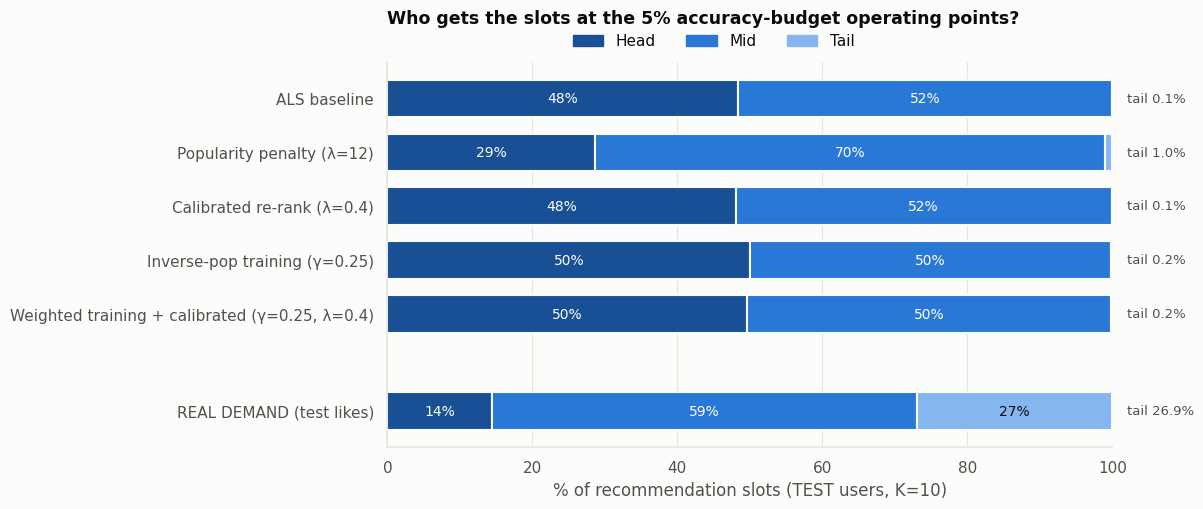

In [24]:
# Compare the accuracy and coverage trade-offs


METHOD_COL = {"Popularity penalty": "#2a78d6", "Calibrated re-rank": "#eb6834",
              "Inverse-pop training": "#1baf7a", "Weighted training + calibrated": "#eda100"}
base_row = SW_TEST["Calibrated re-rank"][0].iloc[0]
REF = 5


panels = [("effective_titles", "Effective number of titles\n(higher = attention spread wider)"),
          ("tail_%",          "% of slots to tail titles"),
          ("genre_TVD",       "Genre mismatch vs. own history\n(lower = better calibrated)")]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.4))
for ax, (metric, ylab) in zip(axes, panels):
    for m, (df, _, _) in SW_TEST.items():
        d = df[df["rel_NDCG_%"] >= 80]
        ax.plot(d["rel_NDCG_%"], d[metric], color=METHOD_COL[m], lw=2, marker="o", ms=6, mec=SURF, mew=1.2, label=m, zorder=2)
        r = op_tbl[(op_tbl.method == m) & (op_tbl.budget == f"{REF}%")].iloc[0]
        ax.scatter(r["rel_NDCG_%"], r[metric], s=190, facecolor="none", edgecolor=INK, lw=1.8, zorder=4)
    ax.scatter(100, base_row[metric], marker="D", s=80, color=INK, zorder=5)
    ax.annotate("ALS baseline", (100, base_row[metric]), xytext=(8, -14), textcoords="offset points",
                ha="left", fontsize=9.5, color=INK, bbox=dict(facecolor=SURF, edgecolor="none", pad=1.5))
    ax.set_xlim(80, 104)
    ax.set_xlabel("NDCG@10, % of baseline ALS  (left = less accurate)", fontsize=10)
    ax.set_ylabel(ylab, fontsize=10); clean(ax, "both")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=4, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 0.965))
fig.suptitle("Accuracy vs. exposure and calibration (TEST users; ringed = 5% budget pick)",
             x=0.01, y=0.995, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.90)); plt.show()


rows = [("ALS baseline", SW_TEST["Calibrated re-rank"][2][0])]
for m in SW_TEST:
    p = op_tbl[(op_tbl.method == m) & (op_tbl.budget == f"{REF}%")].iloc[0]["param"]
    tag = {"Popularity penalty": f"λ={p:g}", "Calibrated re-rank": f"λ={p:g}", "Inverse-pop training": f"γ={p:g}",
           CM: f"γ={g_star:g}, λ={p:g}"}[m]
    rows.append((f"{m} ({tag})", SW_TEST[m][2][p]))
shares = [(lab, 100 * np.bincount(GRP[r.ravel()], minlength=3) / r.size) for lab, r in rows] \
         + [("REAL DEMAND (test likes)", 100 * demand_share)]

fig, ax = plt.subplots(figsize=(12.5, 5))
ypos = list(range(len(rows))) + [len(rows) + 0.8]
for y, (lab, v) in zip(ypos, shares):
    left = 0
    for g, val, col in zip(GRP_NAMES, v, [TIER["head"], TIER["mid"], TIER["tail"]]):
        ax.barh(y, val, left=left, color=col, edgecolor=SURF, linewidth=1.5, height=0.7)
        if val >= 7: ax.text(left + val / 2, y, f"{val:.0f}%", ha="center", va="center", fontsize=10,
                             color="white" if g != "tail" else INK)
        left += val
    ax.text(102, y, f"tail {v[2]:.1f}%", va="center", ha="left", fontsize=9.5, color=INK2,
            bbox=dict(facecolor=SURF, edgecolor="none", pad=1.5), zorder=5)
ax.set_yticks(ypos); ax.set_yticklabels([s[0] for s in shares]); ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.set_xlabel("% of recommendation slots (TEST users, K=10)"); clean(ax)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=TIER[g]) for g in GRP_NAMES], labels=["Head", "Mid", "Tail"],
          ncol=3, frameon=False, loc="lower center", bbox_to_anchor=(0.45, 1.0))
ax.set_title(f"Who gets the slots at the {REF}% accuracy-budget operating points?", loc="left", pad=28)
fig.subplots_adjust(left=0.30, right=0.88); plt.show()


In [25]:
# Set up the recommendation feedback simulation





SIM_FAST    = True
SIM_N_USERS = 3000 if SIM_FAST else 6000
SIM_N_ITEMS = 8000
SIM_ROUNDS  = 24 if SIM_FAST else 30
N_SIM       = SIM_N_USERS
rng_w       = np.random.default_rng(RANDOM_SEED)
SIM_USERS   = np.sort(rng_w.choice(EVAL_USERS, size=min(SIM_N_USERS, len(EVAL_USERS)), replace=False))
SIM_ITEMS   = np.sort(np.argsort(-pop_train, kind="stable")[:SIM_N_ITEMS])
N_SIM       = len(SIM_USERS); N_SIM_ITEMS = len(SIM_ITEMS)
u_map = np.full(N_USERS, -1, np.int32); u_map[SIM_USERS] = np.arange(N_SIM)
i_map = np.full(N_ITEMS, -1, np.int32); i_map[SIM_ITEMS] = np.arange(N_SIM_ITEMS)


GRP_SIM  = define_popularity_groups(pop_train[SIM_ITEMS])
G_SIM    = G[SIM_ITEMS]; Gn_SIM = Gn[SIM_ITEMS]
pop_pct_sim = rankdata(pop_train[SIM_ITEMS]) / N_SIM_ITEMS
sub = lambda M: M[SIM_USERS][:, SIM_ITEMS].tocsr()
X_hist, X_pos0 = sub(X_train_ratings), sub(X_train_pos)
print(f"simulated world: {N_SIM:,} users x {N_SIM_ITEMS:,} titles | initial likes {X_pos0.nnz:,} | head/mid/tail titles: {np.bincount(GRP_SIM, minlength=3).tolist()}")




def _explicit_half_step(X, Y, reg):
    """ALS for explicit ratings (ALS-WR): ridge regression of each row's ratings on the other side's factors"""
    f = Y.shape[1]; out = np.zeros((X.shape[0], f)); I = np.eye(f)
    for u in range(X.shape[0]):
        s, e = X.indptr[u], X.indptr[u + 1]
        if e == s: continue
        Yu = Y[X.indices[s:e]]
        out[u] = np.linalg.solve(Yu.T @ Yu + reg * (e - s) * I, Yu.T @ X.data[s:e])
    return out

def world_ratings(df):
    """ratings of simulated users on active-catalog titles, as (user, item, rating) arrays in world indices"""
    u, i = u_map[df.u.to_numpy()], i_map[df.i.to_numpy()]; m = (u >= 0) & (i >= 0)
    return u[m], i[m], df.rating.to_numpy()[m].astype(float)

def fit_oracle(u, i, r, factors=32, reg=0.1, iters=10, seed=RANDOM_SEED):
    """r_ui ~ mu + b_u + b_i + p_u . q_i. returns the full predicted-rating matrix (sim users x active titles), clipped to [0.5, 5]"""
    nu, ni = N_SIM, N_SIM_ITEMS; mu = r.mean()
    b_i = np.bincount(i, weights=r - mu, minlength=ni) / (np.bincount(i, minlength=ni) + 10)
    b_u = np.bincount(u, weights=r - mu - b_i[i], minlength=nu) / (np.bincount(u, minlength=nu) + 15)
    E = sparse.csr_matrix((r - mu - b_u[u] - b_i[i], (u, i)), shape=(nu, ni)); Et = E.T.tocsr()
    rng = np.random.default_rng(seed); Q = rng.normal(0, 0.1, (ni, factors))
    for _ in range(iters):
        P = _explicit_half_step(E, Q, reg); Q = _explicit_half_step(Et, P, reg)
    return np.clip(mu + b_u[:, None] + b_i[None, :] + P @ Q.T, 0.5, 5).astype(np.float32)


pred_tr = fit_oracle(*world_ratings(sp.train))
te_u, te_i, te_r = world_ratings(sp.test)
rmse = np.sqrt(np.mean((pred_tr[te_u, te_i] - te_r) ** 2))
rmse_const = np.sqrt(np.mean((world_ratings(sp.train)[2].mean() - te_r) ** 2))
print(f"Oracle sanity check (fit on train, predict future ratings): RMSE = {rmse:.3f}  vs  always-predict-the-mean = {rmse_const:.3f}")
del pred_tr


PRED = fit_oracle(*world_ratings(ratings))
LIKE_TEMP = 0.5
def make_rho(threshold=3.5):
    """assumption A1: P(user likes title) = sigmoid((predicted rating - threshold) / 0.5)
    threshold 3.5 ~ 'would rate it 4+ if they watched it', higher = pickier users"""
    return (1.0 / (1.0 + np.exp(-(PRED - threshold) / LIKE_TEMP))).astype(np.float32)
RHO = make_rho(3.5)
print(f"P(like) matrix: mean {RHO.mean():.3f} | share of (user,title) pairs with P(like) > 0.5: {(RHO > 0.5).mean():.1%}")
for g, nm in enumerate(GRP_NAMES):
    print(f"  mean P(like) for {nm:4s} titles: {RHO[:, GRP_SIM == g].mean():.3f}")


simulated world: 3,000 users x 8,000 titles | initial likes 178,861 | head/mid/tail titles: [105, 1735, 6160]
Oracle sanity check (fit on train, predict future ratings): RMSE = 0.867  vs  always-predict-the-mean = 1.036
P(like) matrix: mean 0.515 | share of (user,title) pairs with P(like) > 0.5: 55.1%
  mean P(like) for head titles: 0.684
  mean P(like) for mid  titles: 0.548
  mean P(like) for tail titles: 0.503


In [26]:
# Simulate how recommendations affect future ratings











G_MIT = float(g_star)
L_MIT = float(op_tbl[(op_tbl.method == CM) & (op_tbl.budget == "5%")].param.iloc[0])
ARMS  = {"Baseline ALS": (0.0, 0.0), "Mitigated": (G_MIT, L_MIT)}
print(f"mitigated arm = inverse-popularity training gamma={G_MIT:g} + calibrated re-ranking lambda={L_MIT:g}")

class SimALS:
    """Implicit ALS (optionally inverse-popularity weighted) that can be re-trained from its previous factors. numpy, because the world is small"""
    def __init__(self, gamma, factors=ALS_FACTORS, reg=als_p["reg"], alpha=als_p["alpha"], iters_init=10, iters_warm=3):
        self.g, self.f, self.reg, self.alpha, self.i0, self.i1 = gamma, factors, reg, alpha, iters_init, iters_warm
    def fit(self, Xpos, seed, warm=False):
        cnt = np.maximum(np.asarray(Xpos.sum(axis=0)).ravel(), 1)
        w = cnt ** (-self.g); w = w / ((cnt * w).sum() / cnt.sum())
        C = confidence_matrix(Xpos, self.alpha, w).astype(np.float64); Ct = C.T.tocsr()
        if warm and hasattr(self, "Q"): Q, iters = self.Q.astype(np.float64), self.i1
        else: Q, iters = np.random.default_rng(seed).normal(0, 0.01, (C.shape[1], self.f)), self.i0
        for _ in range(iters):
            P = _half_step(C, Q, self.reg); Q = _half_step(Ct, P, self.reg)
        self.P, self.Q = P.astype(np.float32), Q.astype(np.float32); return self
    def scores(self): return self.P @ self.Q.T

def _topk(scores, K):
    part = np.argpartition(-scores, K, axis=1)[:, :K]
    return np.take_along_axis(part, np.argsort(-np.take_along_axis(scores, part, 1), axis=1), 1)

def _pool(scores, M):
    idx = _topk(scores, M); return idx, np.take_along_axis(scores, idx, 1)

def run_simulation(arm, rounds=None, retrain_every=4, K=TOPK, eta=1.0, rho_full=None, seed=0, label=None, verbose=False):
    """One simulated run of one arm. retrain_every=None -> the model is never retrained (control). One row of metrics per round."""
    rounds = rounds or SIM_ROUNDS; rho = RHO if rho_full is None else rho_full
    gamma, lam = ARMS[arm]; rng = np.random.default_rng(10_000 + seed); n = N_SIM; ar = np.arange(n)[:, None]; NI = N_SIM_ITEMS
    seen = (X_hist > 0).toarray(); gcount = np.asarray(X_pos0 @ Gn_SIM)
    click_u, click_i = [], []
    model = SimALS(gamma).fit(X_pos0, RANDOM_SEED + seed)
    exam = np.arange(1, K + 1, dtype=float) ** (-eta)
    exam_w = np.broadcast_to(exam, (n, K)).ravel()
    imp_cum, clk_cum, ever, rows = np.zeros(NI), np.zeros(NI), np.zeros(NI, bool), []
    for t in range(rounds):
        if retrain_every and t > 0 and t % retrain_every == 0:
            cu, ci = np.concatenate(click_u), np.concatenate(click_i)
            Xpos = X_pos0 + sparse.csr_matrix((np.ones(len(cu), np.float32), (cu, ci)), shape=X_pos0.shape)
            model.fit(Xpos, RANDOM_SEED + seed + t, warm=True)
        sc = model.scores(); sc[seen] = -np.inf
        if lam == 0: recs = _topk(sc, K)
        else:
            idx, ps = _pool(sc, M_POOL); s = gcount.sum(axis=1, keepdims=True)
            p = np.divide(gcount, s, out=np.zeros_like(gcount), where=s > 0).astype(np.float32)
            recs = rerank_calibrated({"idx": idx, "sc": ps, "p": p}, lam, K, Gmat=Gn_SIM)
        rho_shown = rho[ar, recs]
        click = rng.random((n, K)) < exam[None, :] * rho_shown
        cu, ck = np.nonzero(click); ci = recs[cu, ck]
        seen[cu, ci] = True; np.add.at(gcount, cu, Gn_SIM[ci]); click_u.append(cu); click_i.append(ci)
        flat = recs.ravel(); imp = np.bincount(flat, minlength=NI)
        att = np.bincount(flat, weights=exam_w, minlength=NI)
        imp_cum += imp; clk_cum += np.bincount(ci, minlength=NI); ever |= imp > 0
        rows.append({"arm": label or arm, "seed": seed, "round": t + 1,
                     "coverage_round_%": 100 * (imp > 0).mean(), "coverage_cum_%": 100 * ever.mean(),
                     "gini_exposure": gini(att), "effective_titles": effective_titles(att),
                     "head_slots_%": 100 * (GRP_SIM[flat] == 0).mean(), "tail_slots_%": 100 * (GRP_SIM[flat] == 2).mean(),
                     "ILD": intra_list_diversity(recs, G_SIM), "ARP_pct": pop_pct_sim[flat].mean(),
                     "avg_P_like": rho_shown.mean(), "clicks_per_user": click.sum() / n, "ctr_%": 100 * click.mean(),
                     "click_coverage_cum_%": 100 * (clk_cum > 0).mean(), "gini_clicks_cum": gini(clk_cum),
                     "head_click_share_cum_%": 100 * clk_cum[GRP_SIM == 0].sum() / clk_cum.sum()})
        if verbose and (t + 1) % 6 == 0: print(f"  [{arm}, seed {seed}] round {t + 1}/{rounds}")
    return pd.DataFrame(rows)


mitigated arm = inverse-popularity training gamma=0.25 + calibrated re-ranking lambda=0.4


seed 0 done (214s)
seed 1 done (427s)
seed 2 done (635s)
End of simulation (24 rounds, 3,000 users). Per-round metrics = average of the last 4 rounds; mean over 3 seeds.


,coverage_cum_%,click_coverage_cum_%,gini_exposure,effective_titles,head_slots_%,tail_slots_%,ILD,avg_P_like,clicks_per_user_per_round,total_clicks_per_user,head_click_share_cum_%
arm,,,,,,,,,,,
Baseline ALS,10.825,9.625,0.980,213.537,56.800,0.028,0.723,0.708,2.079,51.238,70.051
Mitigated,16.100,14.129,0.976,246.947,50.696,0.189,0.722,0.699,1.977,50.055,57.710
"Baseline, never retrained (control)",13.517,12.400,0.957,454.947,35.194,0.079,0.715,0.688,1.989,49.859,54.408



Mitigated vs. Baseline (per seed):  total clicks per user -2.3% (range -2.3% to -2.3%)  |  effective titles +15.6% (range +14.3% to +16.9%)

Change from round 1 to the end of the simulation (end minus start):


,gini_exposure,effective_titles,coverage_round_%,head_slots_%,tail_slots_%,ILD,avg_P_like
arm,,,,,,,
Baseline ALS,-0.010,112.113,4.667,-22.826,-0.002,0.043,-0.057
Mitigated,-0.012,130.265,8.354,-27.493,0.123,0.025,-0.066
"Baseline, never retrained (control)",-0.032,353.523,7.358,-44.431,0.049,0.035,-0.077


Loop effect = baseline minus control: the part of the change caused by retraining on the model's own clicks.


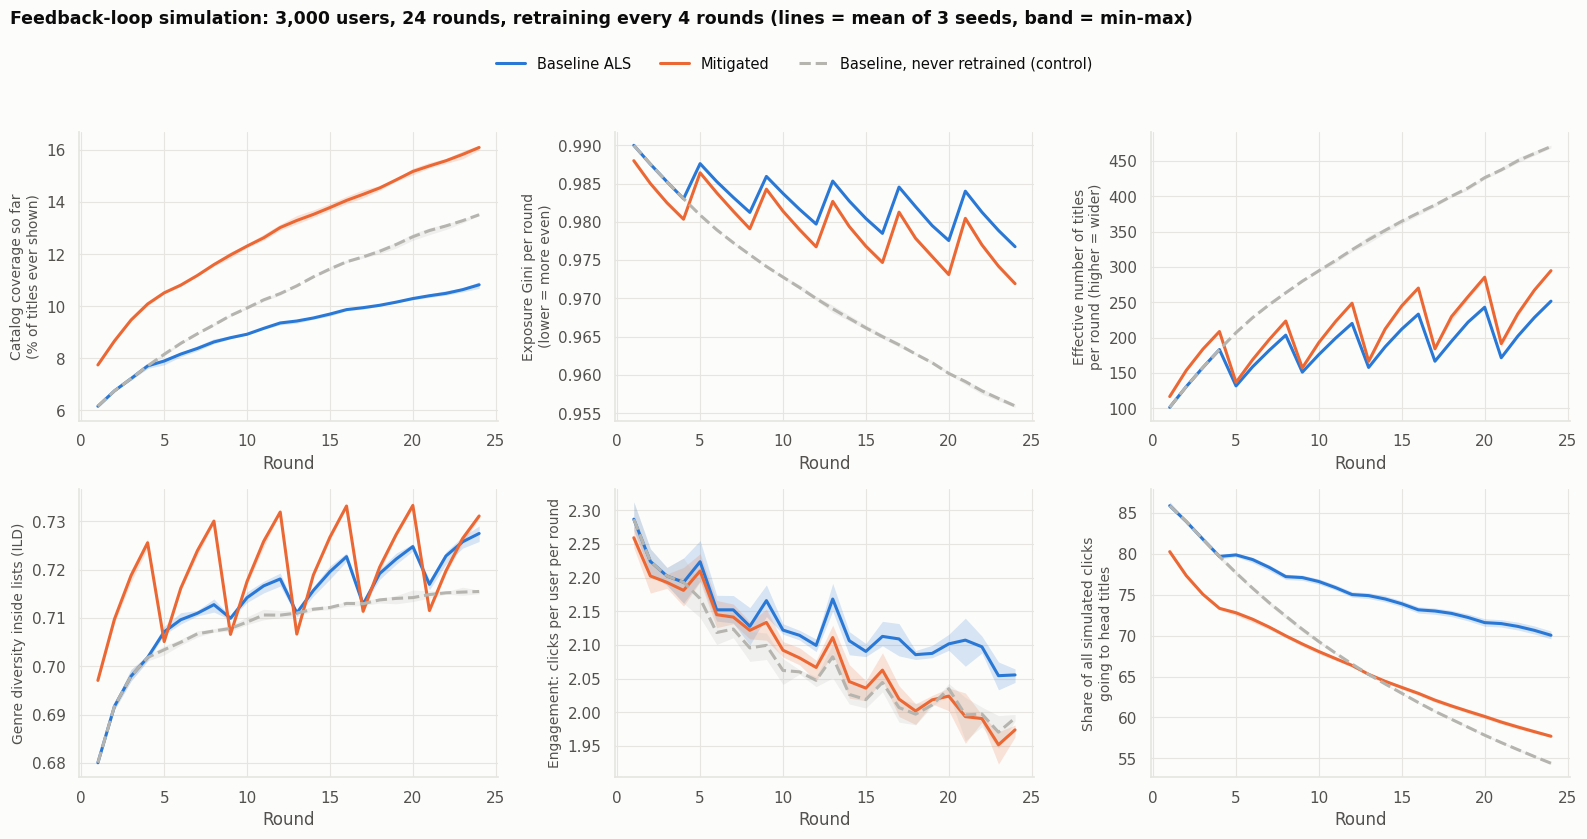

In [27]:
# Compare the main simulation runs


SEEDS, RETRAIN = [0, 1, 2], 4
CONTROL = "Baseline, never retrained (control)"
t0 = time.time(); runs = []
for seed in SEEDS:
    for arm in ARMS: runs.append(run_simulation(arm, retrain_every=RETRAIN, seed=seed))
    runs.append(run_simulation("Baseline ALS", retrain_every=None, seed=seed, label=CONTROL))
    print(f"seed {seed} done ({time.time() - t0:.0f}s)")
MAIN = pd.concat(runs, ignore_index=True)
ORDER_ARMS = ["Baseline ALS", "Mitigated", CONTROL]


def end_state(df, last=4):
    return pd.Series({"coverage_cum_%": df["coverage_cum_%"].iloc[-1], "click_coverage_cum_%": df["click_coverage_cum_%"].iloc[-1],
                      "gini_exposure": df.gini_exposure.tail(last).mean(), "effective_titles": df.effective_titles.tail(last).mean(),
                      "head_slots_%": df["head_slots_%"].tail(last).mean(), "tail_slots_%": df["tail_slots_%"].tail(last).mean(),
                      "ILD": df.ILD.tail(last).mean(), "avg_P_like": df.avg_P_like.tail(last).mean(),
                      "clicks_per_user_per_round": df.clicks_per_user.tail(last).mean(), "total_clicks_per_user": df.clicks_per_user.sum(),
                      "head_click_share_cum_%": df["head_click_share_cum_%"].iloc[-1]})
per_seed = MAIN.groupby(["arm", "seed"]).apply(end_state, include_groups=False)
summary = per_seed.groupby("arm").mean().loc[ORDER_ARMS]
print(f"End of simulation ({SIM_ROUNDS} rounds, {N_SIM:,} users). Per-round metrics = average of the last 4 rounds; mean over {len(SEEDS)} seeds.")
display(summary.round(3))


b = per_seed.xs("Baseline ALS", level="arm"); m = per_seed.xs("Mitigated", level="arm")
eng = (m.total_clicks_per_user / b.total_clicks_per_user - 1) * 100
eff = (m.effective_titles / b.effective_titles - 1) * 100
print(f"\nMitigated vs. Baseline (per seed):  total clicks per user {eng.mean():+.1f}% (range {eng.min():+.1f}% to {eng.max():+.1f}%)"
      f"  |  effective titles {eff.mean():+.1f}% (range {eff.min():+.1f}% to {eff.max():+.1f}%)")


first = MAIN[MAIN["round"] == 1].groupby("arm").mean(numeric_only=True).loc[ORDER_ARMS]
cols = ["gini_exposure", "effective_titles", "coverage_round_%", "head_slots_%", "tail_slots_%", "ILD", "avg_P_like"]
drift = pd.DataFrame({c: summary.loc[ORDER_ARMS, c if c in summary else c.replace("coverage_round_%", "coverage_cum_%")] for c in cols}) - first[cols]
print("\nChange from round 1 to the end of the simulation (end minus start):"); display(drift.round(3))
print("Loop effect = baseline minus control: the part of the change caused by retraining on the model's own clicks.")


COL = {"Baseline ALS": C1, "Mitigated": C2, CONTROL: GREY}; STY = {"Baseline ALS": "-", "Mitigated": "-", CONTROL: "--"}
panels = [("coverage_cum_%", "Catalog coverage so far\n(% of titles ever shown)"), ("gini_exposure", "Exposure Gini per round\n(lower = more even)"),
          ("effective_titles", "Effective number of titles\nper round (higher = wider)"), ("ILD", "Genre diversity inside lists (ILD)"),
          ("clicks_per_user", "Engagement: clicks per user per round"), ("head_click_share_cum_%", "Share of all simulated clicks\ngoing to head titles")]
fig, axes = plt.subplots(2, 3, figsize=(16, 8.4))
for ax, (metric, ylab) in zip(axes.ravel(), panels):
    for arm in ORDER_ARMS:
        g = MAIN[MAIN.arm == arm].groupby("round")[metric]; mean, lo, hi = g.mean(), g.min(), g.max()
        ax.fill_between(mean.index, lo, hi, color=COL[arm], alpha=0.18, lw=0)
        ax.plot(mean.index, mean.values, color=COL[arm], ls=STY[arm], lw=2.2, label=arm)
    ax.set_xlabel("Round"); ax.set_ylabel(ylab, fontsize=10); clean(ax, "both")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=3, frameon=False, fontsize=10.5, bbox_to_anchor=(0.5, 0.955))
fig.suptitle(f"Feedback-loop simulation: {N_SIM:,} users, {SIM_ROUNDS} rounds, retraining every {RETRAIN} rounds (lines = mean of {len(SEEDS)} seeds, band = min-max)",
             x=0.01, y=0.995, ha="left", fontweight="bold", fontsize=12.5)
fig.tight_layout(rect=(0, 0, 1, 0.91)); plt.show()


Position bias (eta): done (711s)
Retraining every (rounds): done (1374s)
Titles shown per user (K): done (1738s)
User pickiness (like threshold): done (2091s)

Mitigated vs. Baseline under each assumption (one seed = 0; defaults: eta=1.0, retrain every 4, K=10, threshold=3.5)


,axis,value,effective_titles_baseline,effective_titles_mitigated,d_effective_titles_%,d_coverage_pts,d_tail_slots_pts,d_clicks_%,d_P_like_pts,d_ILD
0,Position bias (eta),0.0,425.92,579.56,36.07,12.09,0.69,-0.46,-0.27,0.01
1,Position bias (eta),0.5,294.10,372.07,26.51,7.44,0.25,-1.38,-0.98,0.00
2,Position bias (eta),1.0,214.61,248.40,15.74,5.43,0.17,-2.33,-0.85,0.00
3,Position bias (eta),2.0,159.56,133.89,-16.08,3.75,0.08,-4.98,-0.05,-0.02
4,Retraining every (rounds),1.0,171.73,193.64,12.76,5.39,0.15,-4.06,-1.60,0.00
5,Retraining every (rounds),4,214.61,248.40,15.74,5.43,0.17,-2.33,-0.85,0.00
6,Retraining every (rounds),12,346.34,415.45,19.95,5.00,0.18,-0.88,-0.11,0.03
7,Retraining every (rounds),never,458.28,514.04,12.17,4.30,0.20,-0.50,0.07,0.05
8,Titles shown per user (K),5,186.29,185.02,-0.68,4.35,0.11,-3.21,-1.95,0.02
9,Titles shown per user (K),10,214.61,248.40,15.74,5.43,0.17,-2.33,-0.85,0.00


Engagement effect per seed (main experiment): [-2.33, -2.26, -2.34] %  |  std = 0.05 percentage points


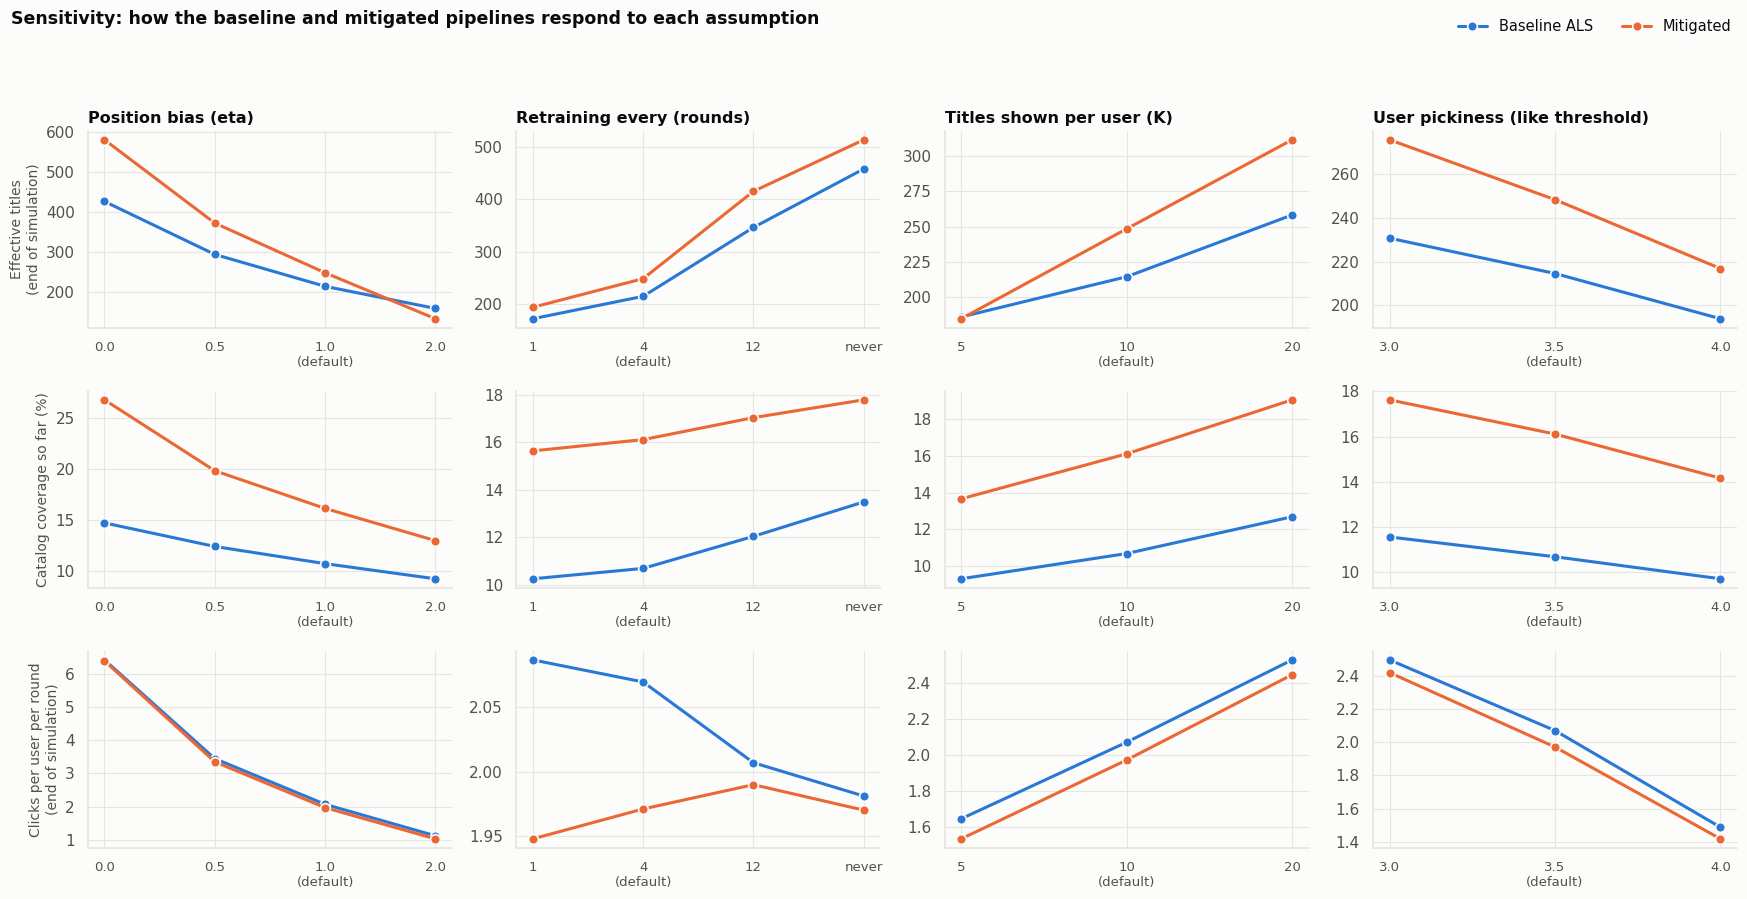

In [28]:
# Check how sensitive the simulation is to assumptions



SENS_AXES = {"Position bias (eta)":              ("eta",           [0.0, 0.5, 1.0, 2.0]),
             "Retraining every (rounds)":        ("retrain_every", [1, 4, 12, None]),
             "Titles shown per user (K)":        ("K",             [5, 10, 20]),
             "User pickiness (like threshold)":  ("tau",           [3.0, 3.5, 4.0])}
DEFAULTS   = {"eta": 1.0, "retrain_every": RETRAIN, "K": TOPK, "tau": 3.5}
RUN_AXES   = list(SENS_AXES)
SENS_SEED  = 0
_cache = globals().get("_cache", {})

def run_config(cfg):
    """run both arms for one configuration (cached, so each config is only simulated once)"""
    key = tuple(sorted(cfg.items(), key=lambda kv: kv[0]))
    if key not in _cache:
        rho = RHO if cfg["tau"] == 3.5 else make_rho(cfg["tau"])
        _cache[key] = {arm: run_simulation(arm, retrain_every=cfg["retrain_every"], K=cfg["K"], eta=cfg["eta"], rho_full=rho, seed=SENS_SEED)
                       for arm in ARMS}
    return _cache[key]

def run_stats(df, last=4):
    return {"coverage_cum_%": df["coverage_cum_%"].iloc[-1], "effective_titles": df.effective_titles.tail(last).mean(),
            "gini": df.gini_exposure.tail(last).mean(), "tail_slots_%": df["tail_slots_%"].tail(last).mean(),
            "ILD": df.ILD.tail(last).mean(), "avg_P_like": df.avg_P_like.tail(last).mean(),
            "clicks_per_user": df.clicks_per_user.tail(last).mean(), "total_clicks_per_user": df.clicks_per_user.sum()}

t0 = time.time(); rows = []
for axis in RUN_AXES:
    name, values = SENS_AXES[axis]
    for v in values:
        cfg = {**DEFAULTS, name: v}; res = run_config(cfg)
        for arm, df in res.items(): rows.append({"axis": axis, "value": "never" if v is None else v, "arm": arm, **run_stats(df)})
    print(f"{axis}: done ({time.time() - t0:.0f}s)")
sens = pd.DataFrame(rows)


d = []
for (axis, value), g in sens.groupby(["axis", "value"], sort=False):
    b, m = g[g.arm == "Baseline ALS"].iloc[0], g[g.arm == "Mitigated"].iloc[0]
    d.append({"axis": axis, "value": value,
              "effective_titles_baseline": b.effective_titles, "effective_titles_mitigated": m.effective_titles,
              "d_effective_titles_%": 100 * (m.effective_titles / b.effective_titles - 1),
              "d_coverage_pts": m["coverage_cum_%"] - b["coverage_cum_%"],
              "d_tail_slots_pts": m["tail_slots_%"] - b["tail_slots_%"],
              "d_clicks_%": 100 * (m.total_clicks_per_user / b.total_clicks_per_user - 1),
              "d_P_like_pts": 100 * (m.avg_P_like - b.avg_P_like), "d_ILD": m.ILD - b.ILD})
effect = pd.DataFrame(d)
print(f"\nMitigated vs. Baseline under each assumption (one seed = {SENS_SEED}; defaults: eta={DEFAULTS['eta']}, retrain every {DEFAULTS['retrain_every']}, K={DEFAULTS['K']}, threshold={DEFAULTS['tau']})")
display(effect.round(2))


if "per_seed" in globals():
    b = per_seed.xs("Baseline ALS", level="arm"); m = per_seed.xs("Mitigated", level="arm")
    eng_seed = (m.total_clicks_per_user / b.total_clicks_per_user - 1) * 100
    print(f"Engagement effect per seed (main experiment): {eng_seed.round(2).tolist()} %  |  std = {eng_seed.std():.2f} percentage points")


rows_m = [("effective_titles", "Effective titles\n(end of simulation)"), ("coverage_cum_%", "Catalog coverage so far (%)"),
          ("clicks_per_user", "Clicks per user per round\n(end of simulation)")]
fig, axes = plt.subplots(len(rows_m), len(RUN_AXES), figsize=(4.4 * len(RUN_AXES), 9), squeeze=False)
for j, axis in enumerate(RUN_AXES):
    vals = [("never" if v is None else v) for v in SENS_AXES[axis][1]]; dflt = DEFAULTS[SENS_AXES[axis][0]]
    for i, (metric, ylab) in enumerate(rows_m):
        ax = axes[i, j]
        for arm, col in [("Baseline ALS", C1), ("Mitigated", C2)]:
            y = [sens[(sens.axis == axis) & (sens.value == v) & (sens.arm == arm)][metric].iloc[0] for v in vals]
            ax.plot(range(len(vals)), y, color=col, lw=2.2, marker="o", ms=7, mec=SURF, mew=1.2, label=arm)
        ax.set_xticks(range(len(vals))); ax.set_xticklabels([f"{v}\n(default)" if v == dflt else str(v) for v in vals], fontsize=9.5)
        if j == 0: ax.set_ylabel(ylab, fontsize=10)
        if i == 0: ax.set_title(axis, loc="left", fontsize=11.5)
        clean(ax, "both")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncol=2, frameon=False, fontsize=10.5, bbox_to_anchor=(0.995, 1.0))
fig.suptitle("Sensitivity: how the baseline and mitigated pipelines respond to each assumption", x=0.01, y=0.995, ha="left", fontweight="bold", fontsize=12.5)
fig.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()


ASSUMPTION-BASED SIMULATION - illustrative, not a forecast. Every dollar figure depends on the assumptions below.
From the Stage 8 simulation (3,000 simulated users): coverage 10.8% -> 16.1% | effective titles +16% | engagement (clicks) -2.3%


,Assumption (all adjustable),base,low,high
key,,,,
subs,Subscribers,1000000.00,NaN,NaN
arpu,Revenue per subscriber per month ($),12.00,NaN,NaN
margin,Contribution margin on a retained subscriber-year,0.35,0.2,0.50
licensed_share,Share of the catalog that is licensed (not owned),0.70,0.4,0.90
license_cost,Average annual licence cost per licensed title...,15000.00,5000.0,30000.00
util_recovery,Share of a title's licence cost 'put to work' ...,0.05,0.0,0.10
eng_churn_per_pct,Retention lost (pp/yr) per 1% fall in engagement,0.05,0.0,0.10
div_churn_per_10pct,Retention gained (pp/yr) per +10% effective ti...,0.03,0.0,0.08



Annual value of the mitigated pipeline vs. baseline (1,000,000 subscribers):


,Pessimistic,Base,Optimistic
engagement cost ($),$-116K,$-58K,$-23K
diversity-retention benefit ($),$0K,$24K,$63K
licence utilisation ($),$0K,$222K,$443K
net annual value ($),$-116K,$187K,$483K
net as % of revenue,-0.08%,+0.13%,+0.34%


Break-even: retention that each +10% in effective titles must deliver (percentage points per year) for the mitigation to pay off.


,Pessimistic,Base,Optimistic
break-even excl. licence (pp per +10% eff. titles),0.148,0.074,0.03
break-even incl. licence (pp per +10% eff. titles),0.148,0.000,0.00



Licence spend on titles that were never recommended in the simulated window: baseline $74.91M vs. mitigated $70.48M (an exposure measure, NOT a saving; with only 3,000 simulated users, coverage understates a real platform's).


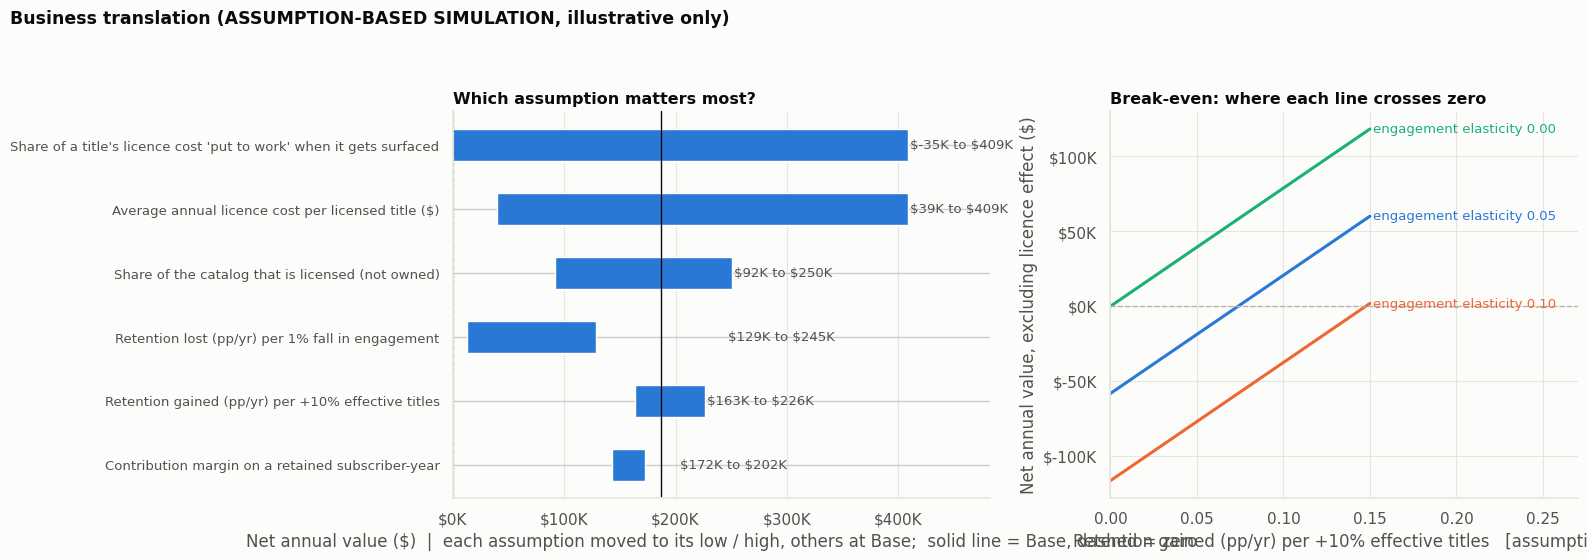

In [29]:
# Estimate the possible business impact





SIM = {"cov_base":  summary.loc["Baseline ALS", "coverage_cum_%"], "cov_mit": summary.loc["Mitigated", "coverage_cum_%"],
       "eff_pct":   100 * (summary.loc["Mitigated", "effective_titles"] / summary.loc["Baseline ALS", "effective_titles"] - 1),
       "click_pct": 100 * (per_seed.xs("Mitigated", level="arm").total_clicks_per_user.mean() /
                           per_seed.xs("Baseline ALS", level="arm").total_clicks_per_user.mean() - 1)}


ASSUME = pd.DataFrame([

 ("subs",             "Subscribers",                                                  1_000_000, None, None),
 ("arpu",             "Revenue per subscriber per month ($)",                         12.0,   None,   None),
 ("margin",           "Contribution margin on a retained subscriber-year",            0.35,   0.20,   0.50),
 ("licensed_share",   "Share of the catalog that is licensed (not owned)",            0.70,   0.40,   0.90),
 ("license_cost",     "Average annual licence cost per licensed title ($)",           15_000, 5_000,  30_000),
 ("util_recovery",    "Share of a title's licence cost 'put to work' when it gets surfaced", 0.05, 0.00, 0.10),
 ("eng_churn_per_pct","Retention lost (pp/yr) per 1% fall in engagement",             0.05,   0.00,   0.10),
 ("div_churn_per_10pct","Retention gained (pp/yr) per +10% effective titles",         0.03,   0.00,   0.08)],
 columns=["key", "assumption", "base", "low", "high"]).set_index("key")
BASE = ASSUME["base"].to_dict()
SCENARIOS = {"Pessimistic": {"util_recovery": 0.0, "eng_churn_per_pct": 0.10, "div_churn_per_10pct": 0.0},
             "Base":        {},
             "Optimistic":  {"util_recovery": 0.10, "eng_churn_per_pct": 0.02, "div_churn_per_10pct": 0.08}}
N_TITLES = N_SIM_ITEMS

def business_case(**over):
    """annual value of switching from the baseline to the mitigated pipeline under one set of assumptions"""
    a = {**BASE, **over}
    value_per_sub = a["arpu"] * 12 * a["margin"]
    pp = lambda p: a["subs"] * (p / 100) * value_per_sub
    d_eng_pp = a["eng_churn_per_pct"] * SIM["click_pct"]
    d_div_pp = a["div_churn_per_10pct"] * SIM["eff_pct"] / 10
    newly_surfaced = (SIM["cov_mit"] - SIM["cov_base"]) / 100 * N_TITLES
    lic = newly_surfaced * a["licensed_share"] * a["license_cost"] * a["util_recovery"]
    out = {"engagement cost ($)": pp(d_eng_pp), "diversity-retention benefit ($)": pp(d_div_pp), "licence utilisation ($)": lic}
    out["net annual value ($)"] = sum(out.values())
    out["net as % of revenue"] = 100 * out["net annual value ($)"] / (a["subs"] * a["arpu"] * 12)

    unit = pp(1) * SIM["eff_pct"] / 10
    out["break-even excl. licence (pp per +10% eff. titles)"] = -out["engagement cost ($)"] / unit
    out["break-even incl. licence (pp per +10% eff. titles)"] = max(0.0, -(out["engagement cost ($)"] + lic) / unit)
    out["_idle_spend_base"] = (1 - SIM["cov_base"] / 100) * N_TITLES * a["licensed_share"] * a["license_cost"]
    out["_idle_spend_mit"]  = (1 - SIM["cov_mit"]  / 100) * N_TITLES * a["licensed_share"] * a["license_cost"]
    return out

fm = lambda x: f"${x / 1e6:,.2f}M" if abs(x) >= 1e6 else f"${x / 1e3:,.0f}K"
fmt_plot = lambda x: fm(x).replace("$", r"\$")
from matplotlib.ticker import FuncFormatter
print("=" * 112); print("ASSUMPTION-BASED SIMULATION - illustrative, not a forecast. Every dollar figure depends on the assumptions below.".center(112)); print("=" * 112)
print(f"From the Stage 8 simulation ({N_SIM:,} simulated users): coverage {SIM['cov_base']:.1f}% -> {SIM['cov_mit']:.1f}% | "
      f"effective titles {SIM['eff_pct']:+.0f}% | engagement (clicks) {SIM['click_pct']:+.1f}%")
display(ASSUME.rename(columns={"assumption": "Assumption (all adjustable)"}))


res = pd.DataFrame({k: business_case(**v) for k, v in SCENARIOS.items()})
show = res.loc[["engagement cost ($)", "diversity-retention benefit ($)", "licence utilisation ($)", "net annual value ($)"]].map(fm)
show.loc["net as % of revenue"] = res.loc["net as % of revenue"].map(lambda x: f"{x:+.2f}%")
print(f"\nAnnual value of the mitigated pipeline vs. baseline ({BASE['subs']:,.0f} subscribers):"); display(show)
print("Break-even: retention that each +10% in effective titles must deliver (percentage points per year) for the mitigation to pay off.")
display(res.loc[["break-even excl. licence (pp per +10% eff. titles)", "break-even incl. licence (pp per +10% eff. titles)"]].round(3))
b = business_case()
print(f"\nLicence spend on titles that were never recommended in the simulated window: baseline {fm(b['_idle_spend_base'])} vs. mitigated {fm(b['_idle_spend_mit'])} "
      f"(an exposure measure, NOT a saving; with only {N_SIM:,} simulated users, coverage understates a real platform's).")


tor = []
for k in ["margin", "licensed_share", "license_cost", "util_recovery", "eng_churn_per_pct", "div_churn_per_10pct"]:
    lo, hi = business_case(**{k: ASSUME.loc[k, "low"]})["net annual value ($)"], business_case(**{k: ASSUME.loc[k, "high"]})["net annual value ($)"]
    tor.append((ASSUME.loc[k, "assumption"], lo, hi))
tor = sorted(tor, key=lambda r: abs(r[2] - r[1]))
base_net = b["net annual value ($)"]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.15, 1]})
for i, (nm, lo, hi) in enumerate(tor):
    ax.barh(i, hi - lo, left=min(lo, hi), height=0.5, color=C1)
    ax.text(max(lo, hi) + 0.01 * abs(base_net + 1), i, f"{fmt_plot(min(lo, hi))} to {fmt_plot(max(lo, hi))}", va="center", fontsize=9.5, color=INK2)
ax.set_yticks(range(len(tor))); ax.set_yticklabels([t[0] for t in tor], fontsize=9.5); ax.axvline(base_net, color=INK, lw=1)
ax.axvline(0, color=GREY, lw=1, ls="--"); ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: fmt_plot(x))); ax.set_xlim(0, ax.get_xlim()[1] * 1.12)
ax.set_xlabel("Net annual value (\\$)  |  each assumption moved to its low / high, others at Base;  solid line = Base, dashed = zero")
ax.set_title("Which assumption matters most?", loc="left", fontsize=11.5); clean(ax, "x")

xs = np.linspace(0, 0.15, 60)
for eng, col in [(0.0, C3), (0.05, C1), (0.10, C2)]:
    ys = [business_case(eng_churn_per_pct=eng, div_churn_per_10pct=x, util_recovery=0.0)["net annual value ($)"] for x in xs]
    ax2.plot(xs, ys, color=col, lw=2.2); ax2.text(xs[-1] + 0.002, ys[-1], f"engagement elasticity {eng:.2f}", color=col, fontsize=9.5, va="center")
ax2.axhline(0, color=GREY, lw=1, ls="--"); ax2.set_xlim(0, 0.27); ax2.yaxis.set_major_formatter(FuncFormatter(lambda x, _: fmt_plot(x)))
ax2.set_xlabel("Retention gained (pp/yr) per +10% effective titles   [assumption]"); ax2.set_ylabel("Net annual value, excluding licence effect (\\$)")
ax2.set_title("Break-even: where each line crosses zero", loc="left", fontsize=11.5); clean(ax2, "both")
fig.suptitle("Business translation (ASSUMPTION-BASED SIMULATION, illustrative only)", x=0.01, y=0.995, ha="left", fontweight="bold", fontsize=12.5)
fig.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()


In [30]:
# Export files for the Streamlit app







import os, json
ART_DIR       = "artifacts"; os.makedirs(ART_DIR, exist_ok=True)
APP_N_ITEMS   = 15_000
EXPORT_USERS_N = 2_000
EXPORT_LAMS   = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
DEFAULT_LAM   = L_MIT

APP_ITEMS = np.sort(np.argsort(-pop_train, kind="stable")[:APP_N_ITEMS])
allowed   = np.zeros(N_ITEMS, bool); allowed[APP_ITEMS] = True
app_of    = np.full(N_ITEMS, -1, np.int32); app_of[APP_ITEMS] = np.arange(len(APP_ITEMS))
EXP_USERS = np.sort(np.random.default_rng(RANDOM_SEED).choice(TEST_USERS, size=min(EXPORT_USERS_N, len(TEST_USERS)), replace=False))
exp_truth = {u: test_rel[u] for u in EXP_USERS}
ctx_e   = make_ctx(als_base,          EXP_USERS, exp_truth, X_seen_test, allowed)
ctx_e_w = make_ctx(wmodels[g_star],   EXP_USERS, exp_truth, X_seen_test, allowed)
assert np.allclose(ctx_e["p"], ctx_e_w["p"]), "both pools must share the same user taste profiles"
assert (app_of[ctx_e["idx"]] >= 0).all() and (app_of[ctx_e_w["idx"]] >= 0).all()
IDX_T = np.int16 if len(APP_ITEMS) < 32767 else np.int32


items = pd.DataFrame({"item_idx": np.arange(len(APP_ITEMS)), "title": movies.title_raw.values[APP_ITEMS], "genres": movies.genres.values[APP_ITEMS],
                      "group": [GRP_NAMES[g] for g in GRP[APP_ITEMS]], "train_count": train_cnt[APP_ITEMS].astype(int), "pop_pct": pop_pct[APP_ITEMS].round(4)})
items.to_csv(f"{ART_DIR}/items.csv", index=False)


np.savez_compressed(f"{ART_DIR}/pools.npz", users=user_ids[EXP_USERS], G=G[APP_ITEMS].astype(np.float32), p=ctx_e["p"].astype(np.float32),
                    base_idx=app_of[ctx_e["idx"]].astype(IDX_T), base_sc=ctx_e["sc"].astype(np.float32),
                    mit_idx=app_of[ctx_e_w["idx"]].astype(IDX_T), mit_sc=ctx_e_w["sc"].astype(np.float32))
sparse.save_npz(f"{ART_DIR}/history.npz", sparse.csr_matrix(X_train_pos[EXP_USERS][:, APP_ITEMS], dtype=np.int8))
sparse.save_npz(f"{ART_DIR}/future.npz",  sparse.csr_matrix(test_pos_mat[EXP_USERS][:, APP_ITEMS], dtype=np.int8))


recs_std = ctx_e["idx"][:, :TOPK]
m_std, nd_std = eval_point(recs_std, ctx_e, True, items=APP_ITEMS)
rows = [{"setting": "standard", "lam": np.nan, **m_std, "rel_NDCG_%": 100.0}]
for lam in EXPORT_LAMS:
    m, _ = eval_point(rerank_calibrated(ctx_e_w, lam), ctx_e_w, True, items=APP_ITEMS)
    rows.append({"setting": "mitigated", "lam": lam, **m, "rel_NDCG_%": 100 * m["NDCG@10"] / m_std["NDCG@10"]})
pd.DataFrame(rows).to_csv(f"{ART_DIR}/pop_metrics.csv", index=False)

json.dump({"gamma": float(g_star), "default_lam": float(DEFAULT_LAM), "lams": EXPORT_LAMS, "K": int(TOPK), "n_users": int(len(EXP_USERS)),
           "genres": list(genres), "relevant_threshold": int(REL_THRESHOLD), "dataset": "MovieLens 32M (ratings to Oct 2023)",
           "n_full_catalog": int(N_ITEMS), "n_app_items": int(len(APP_ITEMS))}, open(f"{ART_DIR}/meta.json", "w"))

total = sum(os.path.getsize(f"{ART_DIR}/{f}") for f in os.listdir(ART_DIR))
print(f"Exported {len(os.listdir(ART_DIR))} files to ./{ART_DIR}  ({total / 1e6:.1f} MB total)  | mitigated model: inverse-popularity ALS gamma={g_star}")
display(pd.DataFrame(rows)[["setting", "lam", "NDCG@10", "rel_NDCG_%", "tail_%", "coverage_%", "effective_titles", "ILD", "genre_TVD"]].round(3))


Exported 6 files to ./artifacts  (3.5 MB total)  | mitigated model: inverse-popularity ALS gamma=0.25


,setting,lam,NDCG@10,rel_NDCG_%,tail_%,coverage_%,effective_titles,ILD,genre_TVD
0,standard,NaN,0.122,100.000,0.030,5.927,411.756,0.662,0.292
1,mitigated,0.00,0.126,103.523,0.190,6.967,424.068,0.656,0.291
2,mitigated,0.10,0.126,103.537,0.205,6.960,423.408,0.662,0.283
3,mitigated,0.20,0.127,103.856,0.225,6.980,423.629,0.667,0.274
4,mitigated,0.30,0.125,102.399,0.205,7.013,425.772,0.672,0.263
5,mitigated,0.40,0.122,100.464,0.205,7.067,428.790,0.675,0.250
6,mitigated,0.50,0.120,98.260,0.230,7.233,435.993,0.676,0.236
7,mitigated,0.60,0.115,94.665,0.310,7.347,445.682,0.677,0.222
8,mitigated,0.70,0.112,91.623,0.410,7.547,459.125,0.677,0.203
9,mitigated,0.80,0.107,87.641,0.460,7.940,481.452,0.675,0.178


In [31]:
# Export item factors for movie suggestions





Qb, Qm = als_base.Q, wmodels[g_star].Q
w_mit = wmodels[g_star].w
np.savez_compressed(f"{ART_DIR}/factors.npz", Q_base=Qb[APP_ITEMS].astype(np.float32), Q_mit=Qm[APP_ITEMS].astype(np.float32),
                    w_mit=w_mit[APP_ITEMS].astype(np.float32), QtQ_base=(Qb.T @ Qb).astype(np.float32), QtQ_mit=(Qm.T @ Qm).astype(np.float32),
                    reg=als_p["reg"], alpha=als_p["alpha"])

def foldin_user(Q, QtQ, liked, w, reg, alpha):
    Yu = Q[liked]; a = alpha * w[liked]
    A = QtQ + (Yu * a[:, None]).T @ Yu + reg * np.eye(Q.shape[1])
    return np.linalg.solve(A, ((1 + a)[:, None] * Yu).sum(axis=0))




chk_users = EXP_USERS[:20]; cos = []
for u in chk_users:
    liked = X_train_pos[u].indices
    if len(liked) == 0: continue
    v = foldin_user(Qm, Qm.T @ Qm, liked, w_mit, als_p["reg"], als_p["alpha"]); t = wmodels[g_star].P[u]
    cos.append(float(v @ t / (np.linalg.norm(v) * np.linalg.norm(t) + 1e-9)))
print(f"fold-in vs trained user vector: mean cosine similarity {np.mean(cos):.3f} over {len(cos)} users")


fold-in vs trained user vector: mean cosine similarity 1.000 over 20 users


In [32]:
# Export simulation results for the app


loop = (MAIN.groupby(["arm", "round"])[["coverage_cum_%", "effective_titles", "head_slots_%", "tail_slots_%", "gini_exposure",
                                         "clicks_per_user", "head_click_share_cum_%"]].mean().reset_index())
loop.to_csv(f"{ART_DIR}/loop.csv", index=False)
assume_rows = ASSUME.reset_index().astype(object).where(ASSUME.reset_index().notna(), None).to_dict("records")
json.dump({"sim": {k: float(v) for k, v in SIM.items()}, "n_titles": int(N_TITLES), "n_sim_users": int(N_SIM), "rounds": int(SIM_ROUNDS),
           "retrain_every": int(RETRAIN), "assume": assume_rows}, open(f"{ART_DIR}/business.json", "w"), indent=1)
print("loop.csv:", loop.shape, "| arms:", list(loop.arm.unique()))
display(loop[loop["round"] == SIM_ROUNDS].round(2))


loop.csv: (72, 9) | arms: ['Baseline ALS', 'Baseline, never retrained (control)', 'Mitigated']


,arm,round,coverage_cum_%,effective_titles,head_slots_%,tail_slots_%,gini_exposure,clicks_per_user,head_click_share_cum_%
23,Baseline ALS,24,10.82,251.73,51.54,0.04,0.98,2.06,70.05
47,"Baseline, never retrained (control)",24,13.52,470.73,33.94,0.08,0.96,1.99,54.41
71,Mitigated,24,16.10,294.93,49.03,0.22,0.97,1.97,57.71


In [33]:
# Gather the final summary numbers


def _f(x): return float(x)
std_row   = audit.loc["ALS"] if "ALS" in audit.index else audit.iloc[0]
pop_row   = audit.loc["Popularity"]
op5       = op_tbl[op_tbl.budget == "5%"].set_index("method")
cmb       = op5.loc[CM]
b_case    = business_case()
b_low     = business_case(**SCENARIOS["Pessimistic"]); b_high = business_case(**SCENARIOS["Optimistic"])
eng_s     = (per_seed.xs("Mitigated", level="arm").total_clicks_per_user / per_seed.xs("Baseline ALS", level="arm").total_clicks_per_user - 1) * 100
RESULTS = {
  "data": {"ratings": int(len(ratings)), "users": int(N_USERS), "titles": int(N_ITEMS), "eval_users": int(len(TEST_USERS)),
           "first_rating": str(to_date([ratings.timestamp.min()])[0].date()), "last_rating": str(to_date([ratings.timestamp.max()])[0].date())},
  "accuracy": {n: _f(PER_USER_TEST[n].ndcg.mean()) for n in ORDER},
  "accuracy_short": {SHORT[n]: _f(PER_USER_TEST[n].ndcg.mean()) for n in ORDER},
  "best_model": SHORT[ORDER[0]],
  "demand_share": {k: _f(v) for k, v in zip(GRP_NAMES, demand_share)},
  "audit_als": {k: _f(std_row[k]) for k in ["head_%", "tail_%", "tail_ratio", "coverage_%", "gini", "effective_titles"]},
  "audit_pop": {k: _f(pop_row[k]) for k in ["head_%", "tail_%", "tail_ratio", "coverage_%", "gini", "effective_titles"]},
  "mitigation_5pct": {"lam": _f(cmb.param), "gamma": _f(g_star), "rel_ndcg_pct": _f(cmb["rel_NDCG_%"]), "dndcg": cmb["dNDCG (95% CI)"],
                      "tail_pct": _f(cmb["tail_%"]), "coverage_pct": _f(cmb["coverage_%"]), "effective_titles": _f(cmb["effective_titles"]),
                      "genre_tvd": _f(cmb["genre_TVD"]), "als_tail_pct": _f(std_row["tail_%"]), "als_effective_titles": _f(std_row["effective_titles"]),
                      "als_coverage_pct": _f(std_row["coverage_%"]), "als_genre_tvd": _f(std_row["genre_TVD"])},
  "simulation": {"users": int(N_SIM), "titles": int(N_SIM_ITEMS), "rounds": int(SIM_ROUNDS), "seeds": len(SEEDS),
                 "cov_base": _f(SIM["cov_base"]), "cov_mit": _f(SIM["cov_mit"]), "eff_pct": _f(SIM["eff_pct"]), "click_pct": _f(SIM["click_pct"]),
                 "click_pct_min": _f(eng_s.min()), "click_pct_max": _f(eng_s.max()),
                 "head_slots_base": _f(summary.loc["Baseline ALS", "head_slots_%"]), "head_slots_mit": _f(summary.loc["Mitigated", "head_slots_%"]),
                 "tail_slots_base": _f(summary.loc["Baseline ALS", "tail_slots_%"]), "tail_slots_mit": _f(summary.loc["Mitigated", "tail_slots_%"])},
  "business": {"net_base": _f(b_case["net annual value ($)"]), "net_low": _f(b_low["net annual value ($)"]), "net_high": _f(b_high["net annual value ($)"]),
               "breakeven_excl_licence": _f(b_case["break-even excl. licence (pp per +10% eff. titles)"]),
               "breakeven_incl_licence": _f(b_case["break-even incl. licence (pp per +10% eff. titles)"]),
               "subs": _f(BASE["subs"])},
}
json.dump(RESULTS, open(f"{ART_DIR}/results.json", "w"), indent=1)
print(json.dumps(RESULTS, indent=1)[:3500])


{
 "data": {
  "ratings": 32000204,
  "users": 200948,
  "titles": 87585,
  "eval_users": 20000,
  "first_rating": "1995-01-09",
  "last_rating": "2023-10-13"
 },
 "accuracy": {
  "Hybrid (ALS + content, alpha=0.5)": 0.12556107409892492,
  "Implicit ALS (f=64, reg=50, a=2)": 0.1249398782892851,
  "PureSVD (f=30)": 0.12324030262839712,
  "Item-kNN CF (k=100)": 0.11820092992982709,
  "Global popularity": 0.07326833705197326,
  "Weighted-rating pop (m=10000)": 0.06427910961674321,
  "Weighted-rating pop (m=250)": 0.033219454203679125,
  "Content-based (genres + decade)": 0.0032360782318329746,
  "Random": 0.00014899551335536448
 },
 "accuracy_short": {
  "Hybrid (ALS+content)": 0.12556107409892492,
  "ALS": 0.1249398782892851,
  "PureSVD": 0.12324030262839712,
  "Item-kNN": 0.11820092992982709,
  "Popularity": 0.07326833705197326,
  "Weighted rating (tuned)": 0.06427910961674321,
  "Weighted rating (m=250)": 0.033219454203679125,
  "Content-based": 0.0032360782318329746,
  "Random": 0.000